In [42]:
# ============================================================
# SECTION 1: IMPORT LIBRARIES
# ============================================================

import os
import sys
import json
import time
import random
import warnings

from pathlib import Path

import numpy as np
import pandas as pd
import rasterio

import timm
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from dataset_utils import EuroSATDataset

from model_utils import (
    create_resnet50,
    create_custom_cnn
)

import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.notebook import tqdm

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    matthews_corrcoef,
    cohen_kappa_score,
    top_k_accuracy_score
)

warnings.filterwarnings("ignore")


# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# Device configuration
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU.")

PyTorch version: 2.11.0+cu128
Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


### Configuration

In [30]:
# ============================================================
# SECTION 2: PROJECT PATHS AND CONFIGURATION
# ============================================================

PROJECT_DIR = Path("..").resolve()

DATA_DIR = PROJECT_DIR / "data" / "raw" / "EuroSAT"

TRAIN_DIR = DATA_DIR / "train"

TEST_DIR = DATA_DIR / "test"

MODEL_DIR = PROJECT_DIR / "models"

OUTPUT_DIR = PROJECT_DIR / "results" / "model_evaluation"


# Model checkpoint paths
MODEL_PATHS = {

    "ResNet50":
        MODEL_DIR / "resnet50_best.pth",

    "EfficientNetV2":
        MODEL_DIR / "efficientnetv2_best.pth",

    "Custom_CNN":
        MODEL_DIR / "custom_cnn_best.pth"

}


# Output directories
METRICS_DIR = OUTPUT_DIR / "metrics"

CONFUSION_DIR = OUTPUT_DIR / "confusion_matrices"

GRAPHS_DIR = OUTPUT_DIR / "comparison_graphs"

PREDICTIONS_DIR = OUTPUT_DIR / "predictions"

TABLES_DIR = OUTPUT_DIR / "report_tables"

EXAMPLES_DIR = OUTPUT_DIR / "classification_examples"

COMPARISON_EXAMPLES_DIR = (
    EXAMPLES_DIR / "three_model_comparisons"
)


# Create all directories
for directory in [
    METRICS_DIR,
    CONFUSION_DIR,
    GRAPHS_DIR,
    PREDICTIONS_DIR,
    TABLES_DIR,
    EXAMPLES_DIR,
    COMPARISON_EXAMPLES_DIR
]:

    directory.mkdir(
        parents=True,
        exist_ok=True
    )


# Dataset configuration
NUM_CLASSES = 10

INPUT_CHANNELS = 13

IMAGE_SIZE = 64

BATCH_SIZE = 32

NUM_WORKERS = 0


# EuroSAT class names
CLASS_NAMES = [
    "Annual Crop",
    "Forest",
    "Herbaceous Vegetation",
    "Highway",
    "Industrial Buildings",
    "Pasture",
    "Permanent Crop",
    "Residential Buildings",
    "River",
    "SeaLake"
]


# Classification example settings
MAX_CORRECT = 5

MAX_INCORRECT = 5

MAX_COMPARISON_EXAMPLES = 10


# Display configuration
sns.set_theme(
    style="whitegrid",
    context="notebook"
)


# Verify paths
print("PROJECT DIRECTORY:", PROJECT_DIR)
print("DATA DIRECTORY:", DATA_DIR)
print("MODEL DIRECTORY:", MODEL_DIR)
print("OUTPUT DIRECTORY:", OUTPUT_DIR)

assert TRAIN_DIR.exists(), "Training directory not found."

assert TEST_DIR.exists(), "Test directory not found."

for model_name, model_path in MODEL_PATHS.items():

    print(
        f"{model_name}:",
        "FOUND" if model_path.exists() else "MISSING"
    )

    assert model_path.exists(), (
        f"Missing checkpoint: {model_path}"
    )

print("\nConfiguration completed.")

PROJECT DIRECTORY: C:\MyDocuments\GitHub Repository\image-classification-project
DATA DIRECTORY: C:\MyDocuments\GitHub Repository\image-classification-project\data\raw\EuroSAT
MODEL DIRECTORY: C:\MyDocuments\GitHub Repository\image-classification-project\models
OUTPUT DIRECTORY: C:\MyDocuments\GitHub Repository\image-classification-project\results\model_evaluation
ResNet50: FOUND
EfficientNetV2: FOUND
Custom_CNN: FOUND

Configuration completed.


### Load models architectures

In [31]:
# ============================================================
# SECTION 3: IMPORT EXISTING MODEL ARCHITECTURES
# ============================================================

sys.path.insert(
    0,
    str(PROJECT_DIR / "src")
)

from model_utils import (
    create_resnet50,
    create_efficientnetv2,
    create_custom_cnn
)


# Register the exact model constructors
MODEL_FACTORIES = {

    "ResNet50": lambda: create_resnet50(
        num_classes=NUM_CLASSES,
        input_channels=INPUT_CHANNELS
    ),

    "EfficientNetV2": lambda: create_efficientnetv2(
        num_classes=NUM_CLASSES,
        input_channels=INPUT_CHANNELS
    ),

    "Custom_CNN": lambda: create_custom_cnn(
        num_classes=NUM_CLASSES,
        input_channels=INPUT_CHANNELS
    )

}


print("Successfully imported model architectures.")

for model_name in MODEL_FACTORIES:
    print("-", model_name)

Successfully imported model architectures.
- ResNet50
- EfficientNetV2
- Custom_CNN


### Load and prepare the EuroSAT dataset

In [32]:
# ================================================
# SECTION 4: LOAD ORIGINAL EURO SAT SPLITS
# ================================================

# ------------------------------------------------
# CONFIGURATION
# ------------------------------------------------

NUM_CLASSES = 10
INPUT_CHANNELS = 13
IMAGE_SIZE = 224
BATCH_SIZE = 8

CLASS_NAMES = [
    "Annual Crop",
    "Forest",
    "Herbaceous Vegetation",
    "Highway",
    "Industrial Buildings",
    "Pasture",
    "Permanent Crop",
    "Residential Buildings",
    "River",
    "SeaLake",
]

# ------------------------------------------------
# LOAD ORIGINAL SPLIT FILES
# ------------------------------------------------

train_df = pd.read_csv("../data/splits/train.csv")
validation_df = pd.read_csv("../data/splits/validation.csv")
test_df = pd.read_csv("../data/splits/test.csv")

print("Original split sizes:")
print("Training:", len(train_df))
print("Validation:", len(validation_df))
print("Testing:", len(test_df))

# ------------------------------------------------
# LOAD ORIGINAL NORMALISATION STATISTICS
# ------------------------------------------------

with open("../data/splits/metadata.json", "r") as file:
    metadata = json.load(file)

TRAIN_MEAN = torch.tensor(
    metadata["band_mean"],
    dtype=torch.float32
)

TRAIN_STD = torch.tensor(
    metadata["band_std"],
    dtype=torch.float32
)

print("\nOriginal training mean:")
print(TRAIN_MEAN)

print("\nOriginal training standard deviation:")
print(TRAIN_STD)

# ------------------------------------------------
# CREATE DATASETS
# ------------------------------------------------

train_dataset_raw = EuroSATDataset(
    dataframe=train_df,
    mean=TRAIN_MEAN.tolist(),
    std=TRAIN_STD.tolist(),
    image_size=IMAGE_SIZE,
    augment=False
)

validation_dataset_raw = EuroSATDataset(
    dataframe=validation_df,
    mean=TRAIN_MEAN.tolist(),
    std=TRAIN_STD.tolist(),
    image_size=IMAGE_SIZE,
    augment=False
)

test_dataset_raw = EuroSATDataset(
    dataframe=test_df,
    mean=TRAIN_MEAN.tolist(),
    std=TRAIN_STD.tolist(),
    image_size=IMAGE_SIZE,
    augment=False
)

# Preserve the names used by subsequent sections
train_dataset = train_dataset_raw
validation_dataset = validation_dataset_raw
test_dataset = test_dataset_raw

# ------------------------------------------------
# CREATE DATA LOADERS
# ------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# ------------------------------------------------
# VERIFY DATASETS
# ------------------------------------------------

print("\nDATASET VERIFICATION")

print("Training images:", len(train_dataset))
print("Validation images:", len(validation_dataset))
print("Test images:", len(test_dataset))

images, labels = next(iter(test_loader))

print("\nTest batch shape:", images.shape)
print("Expected shape: [8, 13, 224, 224]")

print("Minimum:", images.min().item())
print("Maximum:", images.max().item())
print("Mean:", images.mean().item())
print("Standard deviation:", images.std().item())

assert images.shape[1:] == (13, 224, 224)

print("\nDataset preparation completed successfully.")

Original split sizes:
Training: 16200
Validation: 5400
Testing: 5400

Original training mean:
tensor([1354.4055, 1118.2440, 1042.9298,  947.6262, 1199.4729, 1999.7909,
        2369.2229, 2296.8262,  732.0834,   12.1133, 1819.0103, 1118.9240,
        2594.1409])

Original training standard deviation:
tensor([ 245.7176,  333.0078,  395.0925,  593.7505,  566.4170,  861.1840,
        1086.6313, 1117.9817,  404.9198,    4.7758, 1002.5877,  761.3032,
        1231.5858])

DATASET VERIFICATION
Training images: 16200
Validation images: 5400
Test images: 5400

Test batch shape: torch.Size([8, 13, 224, 224])
Expected shape: [8, 13, 224, 224]
Minimum: -1.2800413370132446
Maximum: 4.629651069641113
Mean: 0.6119924187660217
Standard deviation: 0.782396674156189

Dataset preparation completed successfully.


### Calculate training normalisation values

NORMALISATION VERIFICATION
Number of channels: 13
Training mean: tensor([1354.4055, 1118.2440, 1042.9298,  947.6262, 1199.4729, 1999.7909,
        2369.2229, 2296.8262,  732.0834,   12.1133, 1819.0103, 1118.9240,
        2594.1409])
Training standard deviation: tensor([ 245.7176,  333.0078,  395.0925,  593.7505,  566.4170,  861.1840,
        1086.6313, 1117.9817,  404.9198,    4.7758, 1002.5877,  761.3032,
        1231.5858])

DATASET SIZES
Training images: 16200
Validation images: 5400
Test images: 5400

IMAGE PREPROCESSING VERIFICATION
Batch shape: torch.Size([8, 13, 224, 224])
Expected shape: (8, 13, 224, 224)
Minimum pixel value: -1.2800413370132446
Maximum pixel value: 4.629651069641113
Mean: 0.6119924187660217
Standard deviation: 0.782396674156189

CLASS LABEL VERIFICATION
Class names:
0: Annual Crop
1: Forest
2: Herbaceous Vegetation
3: Highway
4: Industrial Buildings
5: Pasture
6: Permanent Crop
7: Residential Buildings
8: River
9: SeaLake

IMAGE PATH VERIFICATION
1. C:\MyDocum

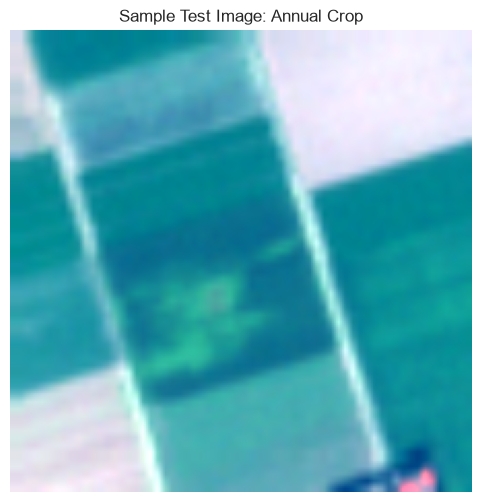


PREPROCESSING COMPLETED
Image size: 224 x 224
Input channels: 13
Normalisation: Original training statistics
Augmentation: Disabled for evaluation
Training samples: 16200
Validation samples: 5400
Testing samples: 5400

All dataset checks passed.


In [34]:
# ================================================
# SECTION 5: DATASET PREPROCESSING AND VERIFICATION
# ================================================

import torch
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------
# 1. VERIFY NORMALISATION STATISTICS
# ------------------------------------------------

print("=" * 60)
print("NORMALISATION VERIFICATION")
print("=" * 60)

assert len(TRAIN_MEAN) == INPUT_CHANNELS
assert len(TRAIN_STD) == INPUT_CHANNELS

assert torch.all(TRAIN_STD > 0)

print("Number of channels:", len(TRAIN_MEAN))
print("Training mean:", TRAIN_MEAN)
print("Training standard deviation:", TRAIN_STD)

# ------------------------------------------------
# 2. VERIFY DATASET SIZES
# ------------------------------------------------

print("\n" + "=" * 60)
print("DATASET SIZES")
print("=" * 60)

print("Training images:", len(train_dataset))
print("Validation images:", len(validation_dataset))
print("Test images:", len(test_dataset))

assert len(train_dataset) == len(train_df)
assert len(validation_dataset) == len(validation_df)
assert len(test_dataset) == len(test_df)

# ------------------------------------------------
# 3. VERIFY IMAGE DIMENSIONS AND NORMALISATION
# ------------------------------------------------

print("\n" + "=" * 60)
print("IMAGE PREPROCESSING VERIFICATION")
print("=" * 60)

images, labels = next(iter(test_loader))

print("Batch shape:", images.shape)
print("Expected shape:", (BATCH_SIZE, 13, 224, 224))

print("Minimum pixel value:", images.min().item())
print("Maximum pixel value:", images.max().item())
print("Mean:", images.mean().item())
print("Standard deviation:", images.std().item())

assert images.shape[1:] == (13, 224, 224)

# ------------------------------------------------
# 4. VERIFY LABELS
# ------------------------------------------------

print("\n" + "=" * 60)
print("CLASS LABEL VERIFICATION")
print("=" * 60)

print("Class names:")

for index, name in enumerate(CLASS_NAMES):
    print(f"{index}: {name}")

assert test_df["label"].min() == 0
assert test_df["label"].max() == NUM_CLASSES - 1

# ------------------------------------------------
# 5. VERIFY IMAGE PATHS
# ------------------------------------------------

print("\n" + "=" * 60)
print("IMAGE PATH VERIFICATION")
print("=" * 60)

for index in range(5):
    image_path = test_df.iloc[index]["image_path"]

    print(f"{index + 1}. {image_path}")

# ------------------------------------------------
# 6. DISPLAY SAMPLE IMAGE
# ------------------------------------------------

print("\n" + "=" * 60)
print("SAMPLE IMAGE")
print("=" * 60)

sample_image, sample_label = test_dataset[0]

# Sentinel-2 RGB bands:
# Band 4 = Red
# Band 3 = Green
# Band 2 = Blue

rgb = sample_image[[3, 2, 1]].clone()

# Convert normalised bands back to their original scale
for i, band_index in enumerate([3, 2, 1]):
    rgb[i] = (
        rgb[i] * TRAIN_STD[band_index]
        + TRAIN_MEAN[band_index]
    )

# Percentile stretch for visualisation
rgb_min = torch.quantile(rgb, 0.02)
rgb_max = torch.quantile(rgb, 0.98)

rgb = (rgb - rgb_min) / (rgb_max - rgb_min + 1e-8)
rgb = torch.clamp(rgb, 0, 1)

rgb = rgb.permute(1, 2, 0).cpu().numpy()

plt.figure(figsize=(6, 6))
plt.imshow(rgb)
plt.title(
    f"Sample Test Image: {CLASS_NAMES[sample_label]}"
)
plt.axis("off")
plt.show()

# ------------------------------------------------
# 7. FINAL VERIFICATION
# ------------------------------------------------

print("\n" + "=" * 60)
print("PREPROCESSING COMPLETED")
print("=" * 60)

print("Image size: 224 x 224")
print("Input channels: 13")
print("Normalisation: Original training statistics")
print("Augmentation: Disabled for evaluation")
print("Training samples:", len(train_dataset))
print("Validation samples:", len(validation_dataset))
print("Testing samples:", len(test_dataset))

print("\nAll dataset checks passed.")

### Load saved models

In [50]:
# ============================================================
# SECTION 6: LOAD ALL THREE TRAINED MODELS
# ============================================================

# ------------------------------------------------------------
# 2. CHECKPOINT PATHS
# ------------------------------------------------------------
def resolve_checkpoint_path(path):

    path = Path(path)

    candidates = [
        path,
        Path.cwd() / path,
        Path.cwd().parent / path,
        Path.cwd() / ".." / path
    ]

    for candidate in candidates:

        candidate = candidate.resolve()

        if candidate.is_file():
            return candidate

    raise FileNotFoundError(
        f"Could not find checkpoint: {path}\n"
        f"Current working directory: {Path.cwd()}"
    )


# ------------------------------------------------------------
# 3. CHECKPOINT LOADING FUNCTION
# ------------------------------------------------------------

def load_model_checkpoint(model, checkpoint_path, model_name):

    checkpoint_path = resolve_checkpoint_path(checkpoint_path)

    print(f"\nLoading {model_name}")
    print("Checkpoint:", checkpoint_path)

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    # Support checkpoints containing metadata or raw state dictionaries.
    if isinstance(checkpoint, dict):

        if "model_state_dict" in checkpoint:
            state_dict = checkpoint["model_state_dict"]

        elif "state_dict" in checkpoint:
            state_dict = checkpoint["state_dict"]

        elif "model" in checkpoint and isinstance(
            checkpoint["model"], dict
        ):
            state_dict = checkpoint["model"]

        else:
            state_dict = checkpoint

    else:
        raise ValueError(
            f"Unexpected checkpoint format for {model_name}"
        )

    # Load trained weights.
    model.load_state_dict(
        state_dict,
        strict=True
    )

    model = model.to(device)
    model.eval()

    # Display checkpoint metadata if available.
    if isinstance(checkpoint, dict):

        if "epoch" in checkpoint:
            print("Checkpoint epoch:", checkpoint["epoch"])

        if "best_validation_macro_f1" in checkpoint:
            print(
                "Best validation Macro F1:",
                checkpoint["best_validation_macro_f1"]
            )

    print(f"{model_name} loaded successfully.")

    return model


# ------------------------------------------------------------
# 4. CREATE RESNET50
# ------------------------------------------------------------

resnet50_model = create_resnet50(
    num_classes=NUM_CLASSES,
    input_channels=INPUT_CHANNELS
)

resnet50_model = load_model_checkpoint(
    model=resnet50_model,
    checkpoint_path=MODEL_PATHS["ResNet50"],
    model_name="ResNet50"
)


# ------------------------------------------------------------
# 5. CREATE EFFICIENTNETV2
# ------------------------------------------------------------

efficientnet_model = timm.create_model(
    "efficientnetv2_rw_m",
    pretrained=False,
    in_chans=INPUT_CHANNELS,
    num_classes=NUM_CLASSES
)

efficientnet_model = load_model_checkpoint(
    model=efficientnet_model,
    checkpoint_path=MODEL_PATHS["EfficientNetV2"],
    model_name="EfficientNetV2"
)


# ------------------------------------------------------------
# 6. CREATE CUSTOM CNN
# ------------------------------------------------------------

custom_cnn_model = create_custom_cnn(
    num_classes=NUM_CLASSES,
    input_channels=INPUT_CHANNELS
)

custom_cnn_model = load_model_checkpoint(
    model=custom_cnn_model,
    checkpoint_path=MODEL_PATHS["Custom_CNN"],
    model_name="Custom_CNN"
)


# ------------------------------------------------------------
# 7. STORE ALL MODELS
# ------------------------------------------------------------

models = {
    "ResNet50": resnet50_model,
    "EfficientNetV2": efficientnet_model,
    "Custom_CNN": custom_cnn_model
}


# ------------------------------------------------------------
# 8. VERIFY LOADED MODELS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("MODEL LOADING SUMMARY")
print("=" * 60)

for model_name, model in models.items():

    total_parameters = sum(
        parameter.numel()
        for parameter in model.parameters()
    )

    print(f"\n{model_name}")
    print("Architecture:", type(model).__name__)
    print("Parameters:", f"{total_parameters:,}")
    print("Device:", next(model.parameters()).device)
    print("Evaluation mode:", not model.training)

print("\nTotal models loaded:", len(models))

assert len(models) == 3, "Not all three models were loaded!"






# ============================================================
# SECTION 6.1: CUSTOM CNN DATASETS AND DATALOADERS
# ============================================================

# Original Custom CNN training image size
CUSTOM_CNN_IMAGE_SIZE = 64

# Use the same normalisation statistics as the other models.
CUSTOM_CNN_MEAN = TRAIN_MEAN
CUSTOM_CNN_STD = TRAIN_STD

# ------------------------------------------------------------
# Validation dataset
# ------------------------------------------------------------

custom_validation_dataset = EuroSATDataset(
    validation_df,
    mean=CUSTOM_CNN_MEAN,
    std=CUSTOM_CNN_STD,
    image_size=CUSTOM_CNN_IMAGE_SIZE,
    augment=False
)

# ------------------------------------------------------------
# Test dataset
# ------------------------------------------------------------

custom_test_dataset = EuroSATDataset(
    test_df,
    mean=CUSTOM_CNN_MEAN,
    std=CUSTOM_CNN_STD,
    image_size=CUSTOM_CNN_IMAGE_SIZE,
    augment=False
)

# ------------------------------------------------------------
# DataLoaders
# ------------------------------------------------------------

custom_validation_loader = DataLoader(
    custom_validation_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

custom_test_loader = DataLoader(
    custom_test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# ------------------------------------------------------------
# Verify dimensions
# ------------------------------------------------------------

images, labels = next(iter(custom_validation_loader))

print("CUSTOM CNN DATASET VERIFICATION")
print("=" * 50)

print("Image shape:", images.shape)
print("Label shape:", labels.shape)
print("Image size:", CUSTOM_CNN_IMAGE_SIZE)
print("Number of channels:", images.shape[1])

assert images.shape[1] == 13
assert images.shape[2] == 64
assert images.shape[3] == 64

print("\nCustom CNN preprocessing configured correctly.")


Loading ResNet50
Checkpoint: C:\MyDocuments\GitHub Repository\image-classification-project\models\resnet50_best.pth
Checkpoint epoch: 9
Best validation Macro F1: 0.9882576447474218
ResNet50 loaded successfully.

Loading EfficientNetV2
Checkpoint: C:\MyDocuments\GitHub Repository\image-classification-project\models\efficientnetv2_best.pth
Checkpoint epoch: 10
Best validation Macro F1: 0.9844310282286332
EfficientNetV2 loaded successfully.

Loading Custom_CNN
Checkpoint: C:\MyDocuments\GitHub Repository\image-classification-project\models\custom_cnn_best.pth
Checkpoint epoch: 10
Best validation Macro F1: 0.9757765210220223
Custom_CNN loaded successfully.

MODEL LOADING SUMMARY

ResNet50
Architecture: ResNet
Parameters: 23,559,882
Device: cuda:0
Evaluation mode: True

EfficientNetV2
Architecture: EfficientNet
Parameters: 51,107,852
Device: cuda:0
Evaluation mode: True

Custom_CNN
Architecture: CustomCNN
Parameters: 1,178,666
Device: cuda:0
Evaluation mode: True

Total models loaded: 3
CU

### Evaluate performance

In [51]:
# ================================================
# SECTION 7: MODEL EVALUATION FUNCTION
# ================================================

import time
import numpy as np
import pandas as pd
import torch

from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    cohen_kappa_score,
    classification_report,
    confusion_matrix,
    top_k_accuracy_score
)


def evaluate_model(model, model_name, test_loader):

    model.eval()

    y_true = []
    y_pred = []
    y_prob = []
    image_paths = []

    inference_times = []

    # ------------------------------------------------
    # WARM-UP
    # ------------------------------------------------

    warmup_images, _ = next(iter(test_loader))

    warmup_images = warmup_images.to(device)

    with torch.no_grad():

        for _ in range(3):
            _ = model(warmup_images)

    # ------------------------------------------------
    # EVALUATION
    # ------------------------------------------------

    total_images = 0

    progress_bar = tqdm(
        test_loader,
        desc=f"Evaluating {model_name}"
    )

    with torch.no_grad():

        for images, labels in progress_bar:

            images = images.to(device)
            labels = labels.to(device)

            # Measure inference time
            if device.type == "cuda":
                torch.cuda.synchronize()

            start_time = time.perf_counter()

            outputs = model(images)

            if device.type == "cuda":
                torch.cuda.synchronize()

            end_time = time.perf_counter()

            batch_time = end_time - start_time

            inference_times.append(batch_time)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )

            predictions = torch.argmax(
                probabilities,
                dim=1
            )

            y_true.extend(
                labels.cpu().numpy()
            )

            y_pred.extend(
                predictions.cpu().numpy()
            )

            y_prob.extend(
                probabilities.cpu().numpy()
            )

            total_images += labels.size(0)

    # ------------------------------------------------
    # CONVERT TO NUMPY
    # ------------------------------------------------

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_prob = np.array(y_prob)

    # Obtain paths from the original test dataframe.
    image_paths = test_df["image_path"].tolist()

    assert len(y_true) == len(test_dataset)
    assert len(y_pred) == len(test_dataset)
    assert len(image_paths) == len(test_dataset)

    # ------------------------------------------------
    # CLASSIFICATION METRICS
    # ------------------------------------------------

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision_macro = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall_macro = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1_macro = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    precision_weighted = precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall_weighted = recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1_weighted = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    balanced_accuracy = balanced_accuracy_score(
        y_true,
        y_pred
    )

    mcc = matthews_corrcoef(
        y_true,
        y_pred
    )

    kappa = cohen_kappa_score(
        y_true,
        y_pred
    )

    top2_accuracy = top_k_accuracy_score(
        y_true,
        y_prob,
        k=2,
        labels=np.arange(NUM_CLASSES)
    )

    # ------------------------------------------------
    # INFERENCE PERFORMANCE
    # ------------------------------------------------

    total_inference_time = sum(inference_times)

    average_batch_time = (
        total_inference_time / len(inference_times)
    )

    average_image_time = (
        total_inference_time / total_images
    )

    images_per_second = (
        total_images / total_inference_time
        if total_inference_time > 0
        else 0
    )

    # ------------------------------------------------
    # CLASSIFICATION REPORT
    # ------------------------------------------------

    report = classification_report(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    # ------------------------------------------------
    # CONFUSION MATRIX
    # ------------------------------------------------

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES)
    )

    # ------------------------------------------------
    # PREDICTION DATAFRAME
    # ------------------------------------------------

    prediction_data = {
        "Image": image_paths,
        "Actual Class": [
            CLASS_NAMES[label] for label in y_true
        ],
        "Predicted Class": [
            CLASS_NAMES[label] for label in y_pred
        ],
        "Actual Label": y_true,
        "Predicted Label": y_pred,
        "Correct": y_true == y_pred,
        "Confidence": np.max(y_prob, axis=1),
        "Actual Class Probability": y_prob[
            np.arange(len(y_true)),
            y_true
        ]
    }

    for class_index, class_name in enumerate(CLASS_NAMES):

        prediction_data[
            f"Probability - {class_name}"
        ] = y_prob[:, class_index]

    predictions_df = pd.DataFrame(
        prediction_data
    )

    # ------------------------------------------------
    # METRICS DICTIONARY
    # ------------------------------------------------

    metrics = {
        "Accuracy": accuracy,
        "Macro Precision": precision_macro,
        "Macro Recall": recall_macro,
        "Macro F1": f1_macro,
        "Weighted Precision": precision_weighted,
        "Weighted Recall": recall_weighted,
        "Weighted F1": f1_weighted,
        "Balanced Accuracy": balanced_accuracy,
        "MCC": mcc,
        "Cohen Kappa": kappa,
        "Top-2 Accuracy": top2_accuracy,
        "Total Inference Time (s)": total_inference_time,
        "Average Batch Time (s)": average_batch_time,
        "Average Image Time (ms)": average_image_time * 1000,
        "Images Per Second": images_per_second,
        "Correct Predictions": int(np.sum(y_true == y_pred)),
        "Incorrect Predictions": int(np.sum(y_true != y_pred)),
        "Total Images": total_images
    }

    # ------------------------------------------------
    # DISPLAY RESULTS
    # ------------------------------------------------

    print(f"\n{model_name} RESULTS")
    print("=" * 50)

    for metric, value in metrics.items():

        if isinstance(value, (float, np.floating)):
            print(f"{metric}: {value:.4f}")
        else:
            print(f"{metric}: {value}")

    # ------------------------------------------------
    # RETURN RESULTS
    # ------------------------------------------------

    return {
        "metrics": metrics,
        "report": report,
        "confusion_matrix": cm,
        "y_true": y_true,
        "y_pred": y_pred,
        "y_prob": y_prob,
        "predictions": predictions_df
    }


print("Model evaluation function defined successfully.")

print("Models available for evaluation:")
for model_name, model in models.items():
    print(f"- {model_name}: {type(model).__name__}")

print(f"\nTotal models loaded: {len(models)}")

Model evaluation function defined successfully.
Models available for evaluation:
- ResNet50: ResNet
- EfficientNetV2: EfficientNet
- Custom_CNN: CustomCNN

Total models loaded: 3


### Evaluate models

In [52]:
# ================================================
# SECTION 8: EVALUATE ALL MODELS
# ================================================

evaluation_results = {}

# Assign the correct test loader to each model.
MODEL_TEST_LOADERS = {
    "ResNet50": test_loader,
    "EfficientNetV2": test_loader,
    "Custom_CNN": custom_test_loader
}

for model_name, model in models.items():

    print("\n" + "=" * 60)
    print(f"EVALUATING {model_name}")
    print("=" * 60)

    # Select the appropriate input resolution.
    current_test_loader = MODEL_TEST_LOADERS[model_name]

    results = evaluate_model(
        model,
        model_name,
        current_test_loader
    )

    evaluation_results[model_name] = results


print("\nALL MODEL EVALUATIONS COMPLETED")


# ------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------

for model_name, results in evaluation_results.items():

    metrics = results["metrics"]

    print(f"\n{model_name}")

    print(
        "Accuracy:",
        round(metrics["Accuracy"], 4)
    )

    print(
        "Macro F1:",
        round(metrics["Macro F1"], 4)
    )

    print(
        "Incorrect predictions:",
        metrics["Incorrect Predictions"]
    )


EVALUATING ResNet50


Evaluating ResNet50:   0%|          | 0/675 [00:00<?, ?it/s]


ResNet50 RESULTS
Accuracy: 0.9876
Macro Precision: 0.9875
Macro Recall: 0.9868
Macro F1: 0.9871
Weighted Precision: 0.9877
Weighted Recall: 0.9876
Weighted F1: 0.9876
Balanced Accuracy: 0.9868
MCC: 0.9862
Cohen Kappa: 0.9862
Top-2 Accuracy: 0.9987
Total Inference Time (s): 25.0271
Average Batch Time (s): 0.0371
Average Image Time (ms): 4.6347
Images Per Second: 215.7660
Correct Predictions: 5333
Incorrect Predictions: 67
Total Images: 5400

EVALUATING EfficientNetV2


Evaluating EfficientNetV2:   0%|          | 0/675 [00:00<?, ?it/s]


EfficientNetV2 RESULTS
Accuracy: 0.9844
Macro Precision: 0.9838
Macro Recall: 0.9834
Macro F1: 0.9836
Weighted Precision: 0.9845
Weighted Recall: 0.9844
Weighted F1: 0.9844
Balanced Accuracy: 0.9834
MCC: 0.9827
Cohen Kappa: 0.9827
Top-2 Accuracy: 0.9978
Total Inference Time (s): 38.5804
Average Batch Time (s): 0.0572
Average Image Time (ms): 7.1445
Images Per Second: 139.9673
Correct Predictions: 5316
Incorrect Predictions: 84
Total Images: 5400

EVALUATING Custom_CNN


Evaluating Custom_CNN:   0%|          | 0/675 [00:00<?, ?it/s]


Custom_CNN RESULTS
Accuracy: 0.9757
Macro Precision: 0.9751
Macro Recall: 0.9744
Macro F1: 0.9746
Weighted Precision: 0.9759
Weighted Recall: 0.9757
Weighted F1: 0.9757
Balanced Accuracy: 0.9744
MCC: 0.9730
Cohen Kappa: 0.9730
Top-2 Accuracy: 0.9944
Total Inference Time (s): 12.1508
Average Batch Time (s): 0.0180
Average Image Time (ms): 2.2501
Images Per Second: 444.4165
Correct Predictions: 5269
Incorrect Predictions: 131
Total Images: 5400

ALL MODEL EVALUATIONS COMPLETED

ResNet50
Accuracy: 0.9876
Macro F1: 0.9871
Incorrect predictions: 67

EfficientNetV2
Accuracy: 0.9844
Macro F1: 0.9836
Incorrect predictions: 84

Custom_CNN
Accuracy: 0.9757
Macro F1: 0.9746
Incorrect predictions: 131


### Comparison table

In [54]:
# ============================================================
# SECTION 9: MODEL PERFORMANCE COMPARISON
# ============================================================

comparison_data = []

for model_name, results in evaluation_results.items():

    metrics = results["metrics"]

    comparison_data.append({

        "Model": model_name,

        "Accuracy": metrics["Accuracy"],

        "Macro Precision": metrics["Macro Precision"],

        "Macro Recall": metrics["Macro Recall"],

        "Macro F1": metrics["Macro F1"],

        "Weighted Precision": metrics["Weighted Precision"],

        "Weighted Recall": metrics["Weighted Recall"],

        "Weighted F1": metrics["Weighted F1"],

        "Balanced Accuracy": metrics["Balanced Accuracy"],

        "MCC": metrics["MCC"],

        "Cohen Kappa": metrics["Cohen Kappa"],

        "Top-2 Accuracy": metrics["Top-2 Accuracy"],

        "Inference Time (s)": metrics["Total Inference Time (s)"],

        "Average Image Time (ms)": metrics["Average Image Time (ms)"],

        "Images Per Second": metrics["Images Per Second"],

        "Correct Predictions": metrics["Correct Predictions"],

        "Incorrect Predictions": metrics["Incorrect Predictions"]
    })


# Create DataFrame
comparison_df = pd.DataFrame(comparison_data)


# Set model as index
comparison_df = comparison_df.set_index("Model")


# Sort by Macro F1
comparison_df = comparison_df.sort_values(
    by="Macro F1",
    ascending=False
)


# Display comparison
display(
    comparison_df.style.format({
        "Accuracy": "{:.4f}",
        "Macro Precision": "{:.4f}",
        "Macro Recall": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Weighted Precision": "{:.4f}",
        "Weighted Recall": "{:.4f}",
        "Weighted F1": "{:.4f}",
        "Balanced Accuracy": "{:.4f}",
        "MCC": "{:.4f}",
        "Cohen Kappa": "{:.4f}",
        "Top-2 Accuracy": "{:.4f}",
        "Inference Time (s)": "{:.2f}",
        "Average Image Time (ms)": "{:.2f}",
        "Images Per Second": "{:.2f}"
    })
)


print("\nMODEL RANKING")
print("=" * 50)

for position, (model_name, row) in enumerate(
    comparison_df.iterrows(),
    start=1
):

    print(
        f"{position}. {model_name} "
        f"- Macro F1: {row['Macro F1']:.4f}"
    )

,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Balanced Accuracy,MCC,Cohen Kappa,Top-2 Accuracy,Inference Time (s),Average Image Time (ms),Images Per Second,Correct Predictions,Incorrect Predictions
Model,,,,,,,,,,,,,,,,
ResNet50,0.9876,0.9875,0.9868,0.9871,0.9877,0.9876,0.9876,0.9868,0.9862,0.9862,0.9987,25.03,4.63,215.77,5333,67
EfficientNetV2,0.9844,0.9838,0.9834,0.9836,0.9845,0.9844,0.9844,0.9834,0.9827,0.9827,0.9978,38.58,7.14,139.97,5316,84
Custom_CNN,0.9757,0.9751,0.9744,0.9746,0.9759,0.9757,0.9757,0.9744,0.9730,0.9730,0.9944,12.15,2.25,444.42,5269,131



MODEL RANKING
1. ResNet50 - Macro F1: 0.9871
2. EfficientNetV2 - Macro F1: 0.9836
3. Custom_CNN - Macro F1: 0.9746


### Classification reports

In [56]:
# ============================================================
# SECTION 10: CLASSIFICATION REPORTS FOR ALL MODELS
# ============================================================

for model_name, results in evaluation_results.items():

    print("\n" + "=" * 70)
    print(model_name.upper())
    print("=" * 70)

    # Convert classification report dictionary to DataFrame
    report_df = pd.DataFrame(results["report"]).transpose()

    # Display rounded classification report
    display(
        report_df.round(4)
    )

    # Display overall metrics
    print("\nOverall Performance:")

    metrics = results["metrics"]

    print(f"Accuracy: {metrics['Accuracy']:.4f}")
    print(f"Macro F1: {metrics['Macro F1']:.4f}")
    print(f"Weighted F1: {metrics['Weighted F1']:.4f}")


RESNET50


,precision,recall,f1-score,support
Annual Crop,0.9785,0.9933,0.9858,596.0000
Forest,0.9983,0.9885,0.9934,608.0000
Herbaceous Vegetation,0.9610,0.9878,0.9742,573.0000
Highway,0.9840,0.9919,0.9880,496.0000
Industrial Buildings,0.9940,0.9840,0.9890,501.0000
Pasture,0.9770,0.9672,0.9721,396.0000
Permanent Crop,0.9924,0.9665,0.9793,538.0000
Residential Buildings,0.9964,0.9964,0.9964,554.0000
River,0.9981,0.9924,0.9953,529.0000
SeaLake,0.9951,1.0000,0.9975,609.0000



Overall Performance:
Accuracy: 0.9876
Macro F1: 0.9871
Weighted F1: 0.9876

EFFICIENTNETV2


,precision,recall,f1-score,support
Annual Crop,0.9832,0.9815,0.9824,596.0000
Forest,0.9885,0.9885,0.9885,608.0000
Herbaceous Vegetation,0.9608,0.9825,0.9715,573.0000
Highway,0.9839,0.9859,0.9849,496.0000
Industrial Buildings,0.9980,0.9860,0.9920,501.0000
Pasture,0.9569,0.9520,0.9544,396.0000
Permanent Crop,0.9924,0.9703,0.9812,538.0000
Residential Buildings,0.9857,0.9982,0.9919,554.0000
River,0.9924,0.9887,0.9905,529.0000
SeaLake,0.9967,1.0000,0.9984,609.0000



Overall Performance:
Accuracy: 0.9844
Macro F1: 0.9836
Weighted F1: 0.9844

CUSTOM_CNN


,precision,recall,f1-score,support
Annual Crop,0.9717,0.9799,0.9758,596.0000
Forest,0.9886,0.9984,0.9935,608.0000
Herbaceous Vegetation,0.9586,0.9703,0.9644,573.0000
Highway,0.9545,0.9718,0.9630,496.0000
Industrial Buildings,0.9938,0.9581,0.9756,501.0000
Pasture,0.9545,0.9545,0.9545,396.0000
Permanent Crop,0.9732,0.9442,0.9585,538.0000
Residential Buildings,0.9752,0.9928,0.9839,554.0000
River,0.9942,0.9735,0.9838,529.0000
SeaLake,0.9870,1.0000,0.9935,609.0000



Overall Performance:
Accuracy: 0.9757
Macro F1: 0.9746
Weighted F1: 0.9757


### Confusion matrices

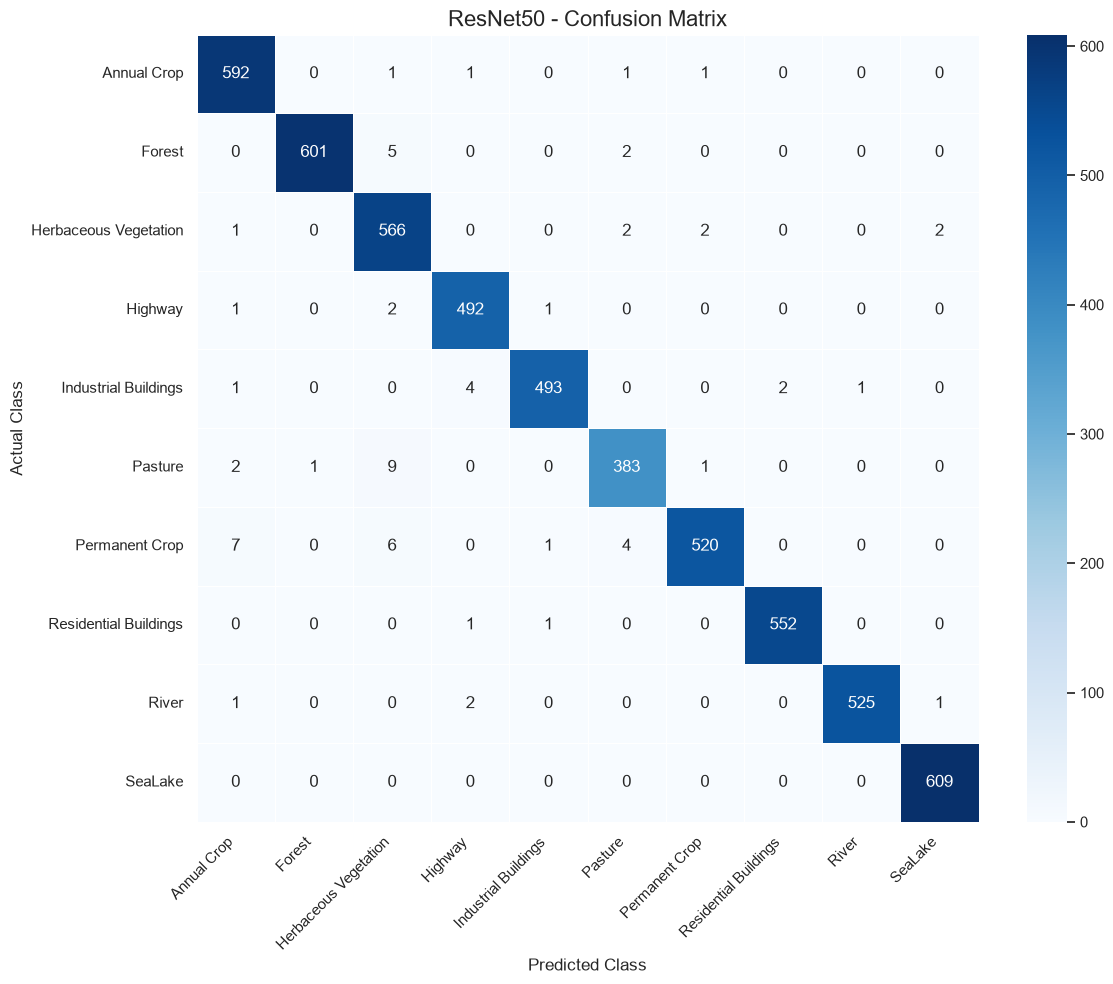

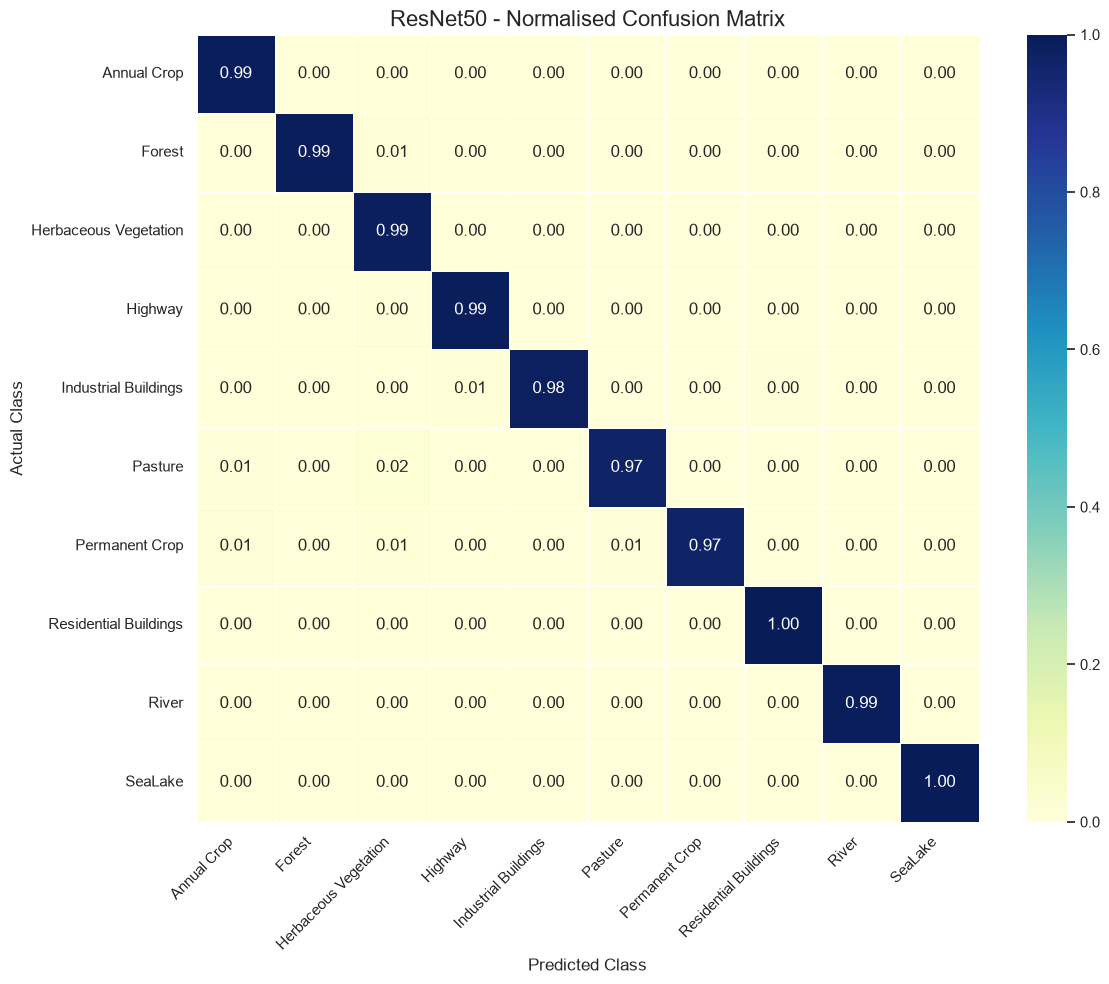

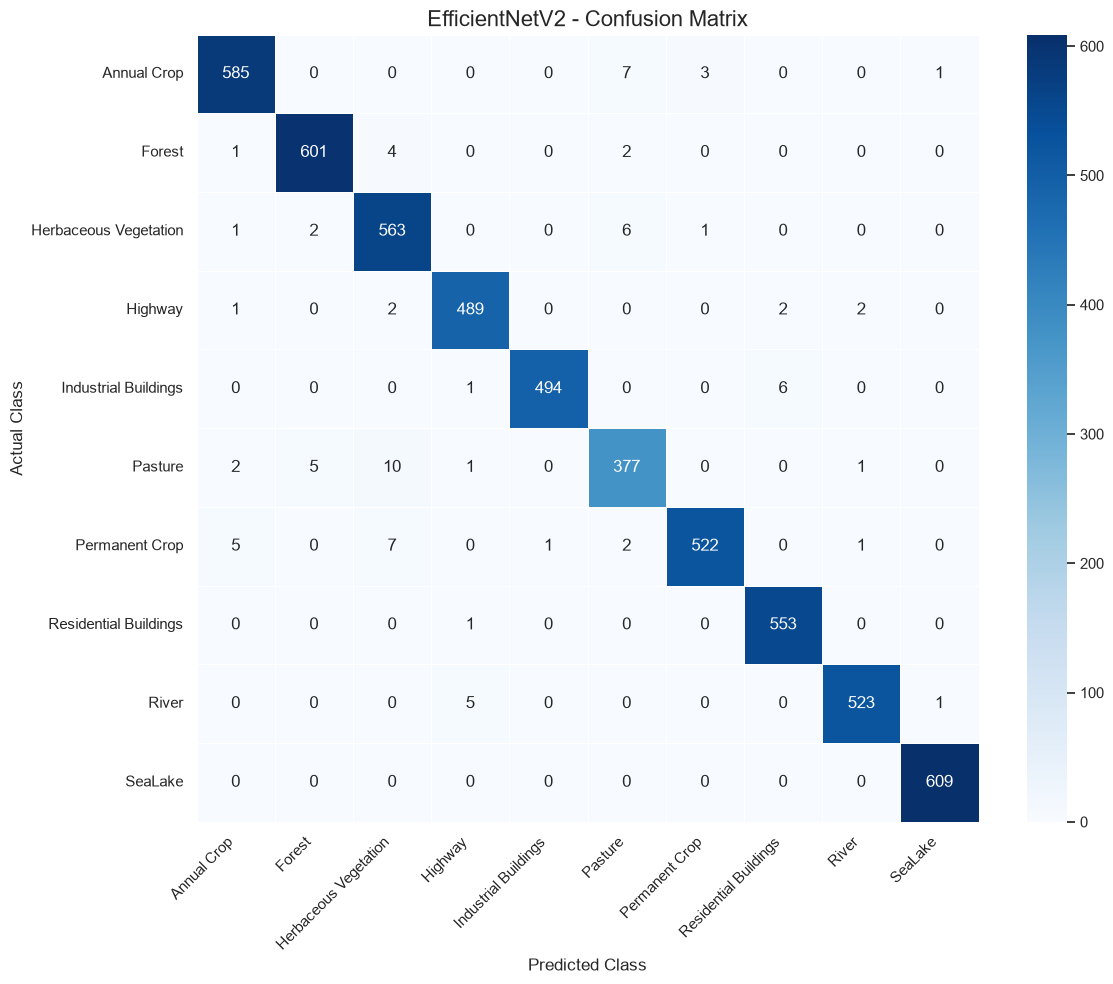

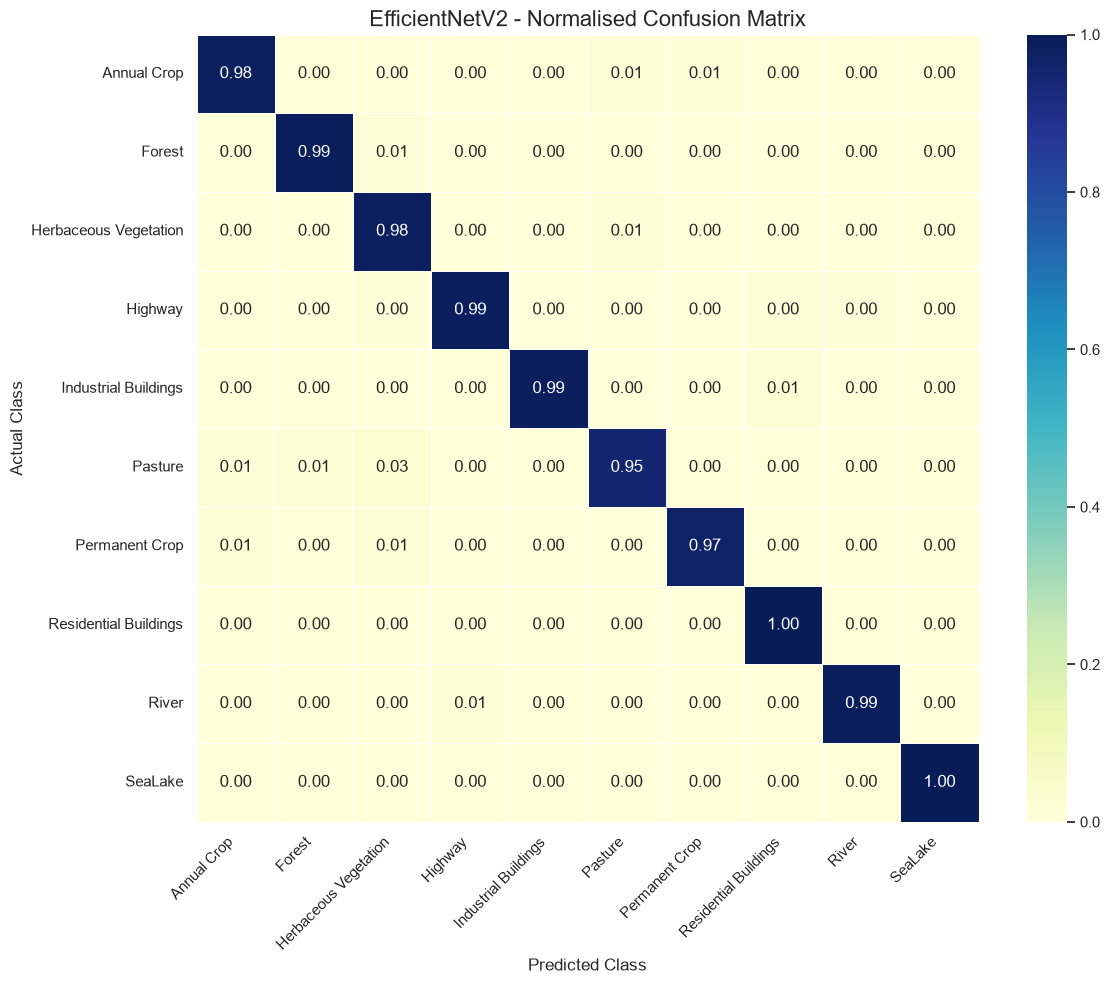

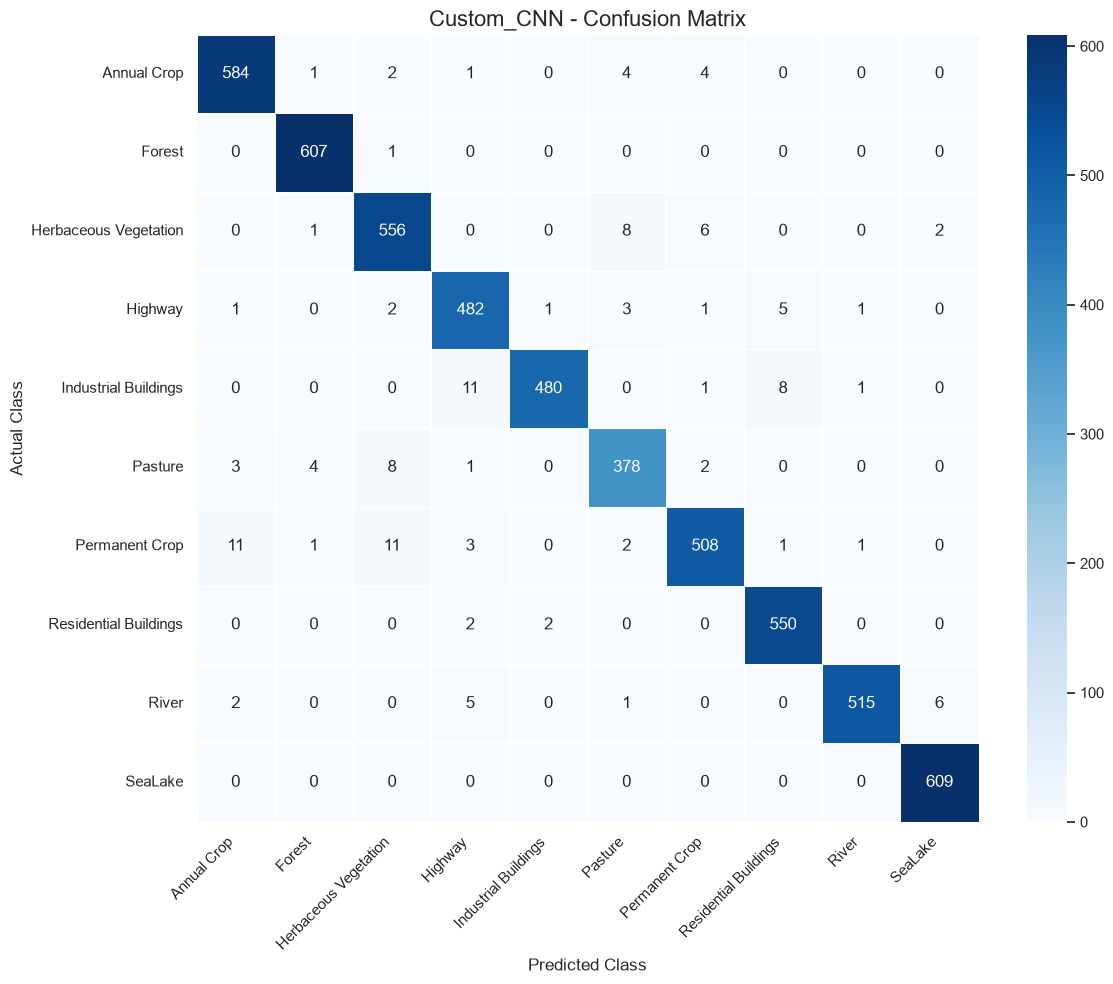

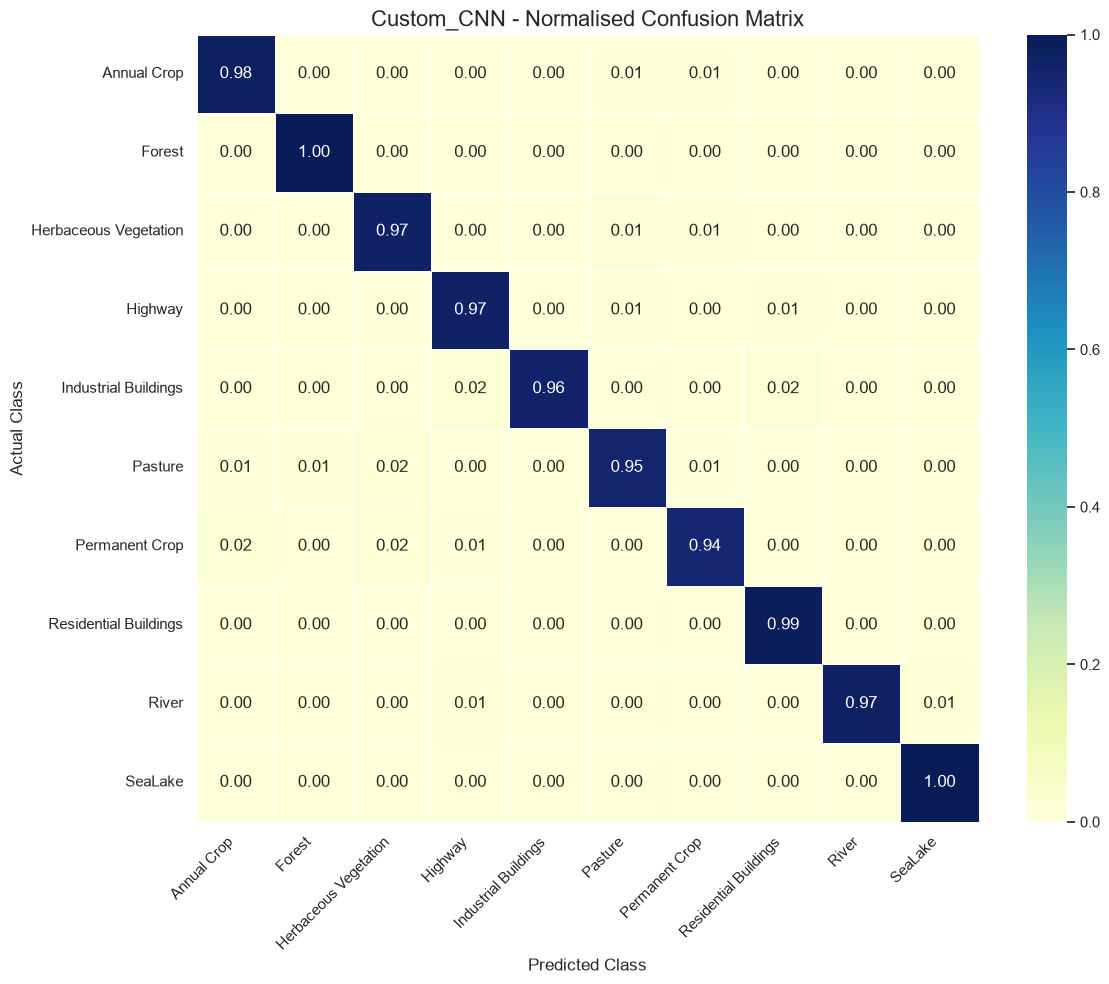

All confusion matrices saved.


In [57]:
# ============================================================
# SECTION 11: CONFUSION MATRICES
# ============================================================

for model_name, results in evaluation_results.items():

    cm = results["confusion_matrix"]


    # --------------------------------------------------------
    # RAW CONFUSION MATRIX
    # --------------------------------------------------------

    plt.figure(figsize=(12, 10))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        linewidths=0.5
    )

    plt.title(
        f"{model_name} - Confusion Matrix",
        fontsize=16
    )

    plt.xlabel("Predicted Class")

    plt.ylabel("Actual Class")

    plt.xticks(
        rotation=45,
        ha="right"
    )

    plt.yticks(rotation=0)

    plt.tight_layout()

    filename = (
        model_name.lower().replace(" ", "_")
        + "_confusion_matrix.png"
    )

    plt.savefig(
        CONFUSION_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


    # --------------------------------------------------------
    # NORMALISED CONFUSION MATRIX
    # --------------------------------------------------------

    cm_normalised = (
        cm.astype(float) /
        np.maximum(
            cm.sum(axis=1, keepdims=True),
            1
        )
    )


    plt.figure(figsize=(12, 10))

    sns.heatmap(
        cm_normalised,
        annot=True,
        fmt=".2f",
        cmap="YlGnBu",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        linewidths=0.5,
        vmin=0,
        vmax=1
    )

    plt.title(
        f"{model_name} - Normalised Confusion Matrix",
        fontsize=16
    )

    plt.xlabel("Predicted Class")

    plt.ylabel("Actual Class")

    plt.xticks(
        rotation=45,
        ha="right"
    )

    plt.yticks(rotation=0)

    plt.tight_layout()

    filename = (
        model_name.lower().replace(" ", "_")
        + "_normalised_confusion_matrix.png"
    )

    plt.savefig(
        CONFUSION_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


    # Save raw confusion matrix as CSV
    pd.DataFrame(
        cm,
        index=CLASS_NAMES,
        columns=CLASS_NAMES
    ).to_csv(
        CONFUSION_DIR /
        f"{model_name.lower().replace(' ', '_')}_confusion_matrix.csv"
    )


print("All confusion matrices saved.")

### Compare accuracy, precision, recall and F1-score

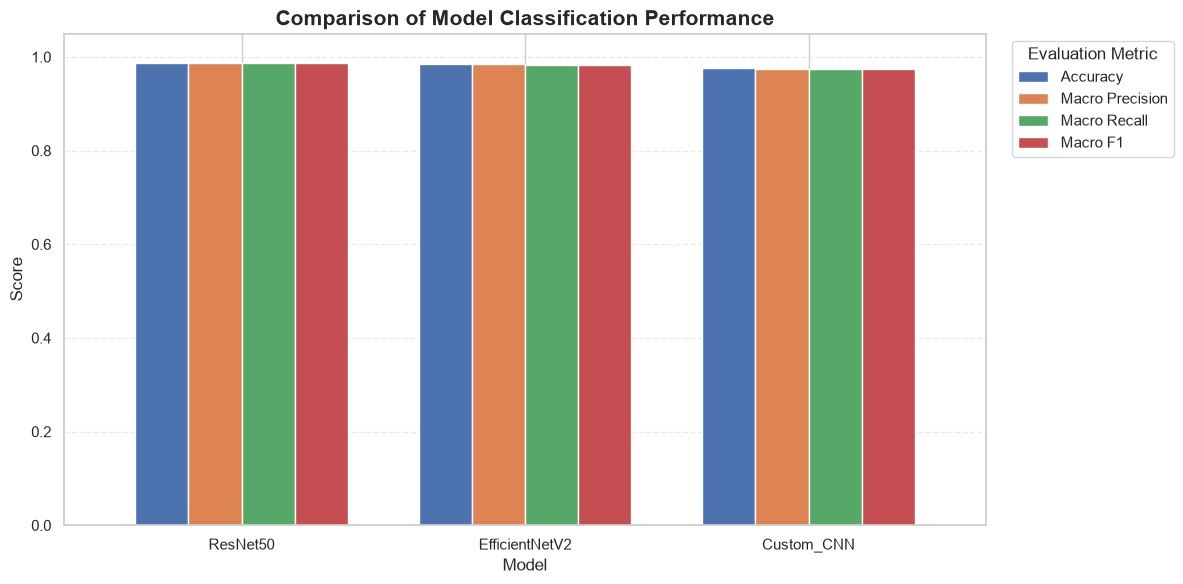

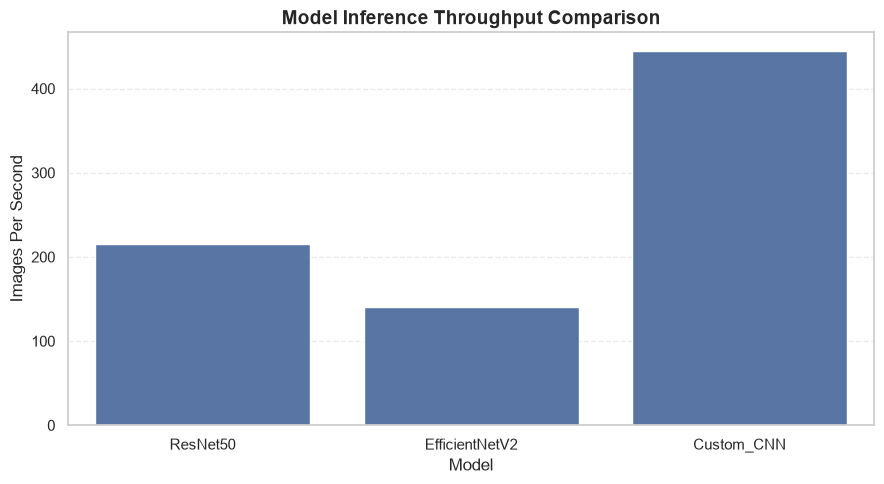

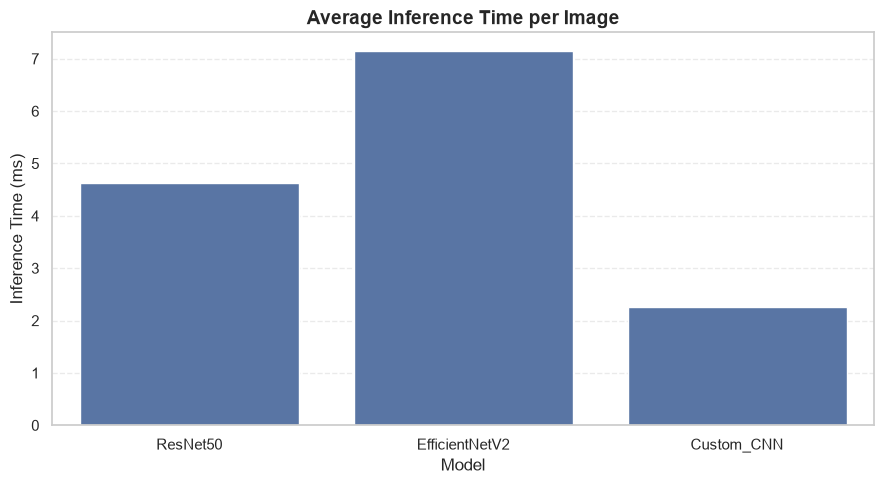

,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Balanced Accuracy,MCC,Cohen Kappa,Top-2 Accuracy,Inference Time (s),Average Image Time (ms),Images Per Second,Correct Predictions,Incorrect Predictions
Model,,,,,,,,,,,,,,,,
ResNet50,0.9876,0.9875,0.9868,0.9871,0.9877,0.9876,0.9876,0.9868,0.9862,0.9862,0.9987,25.0271,4.6347,215.7660,5333,67
EfficientNetV2,0.9844,0.9838,0.9834,0.9836,0.9845,0.9844,0.9844,0.9834,0.9827,0.9827,0.9978,38.5804,7.1445,139.9673,5316,84
Custom_CNN,0.9757,0.9751,0.9744,0.9746,0.9759,0.9757,0.9757,0.9744,0.9730,0.9730,0.9944,12.1508,2.2501,444.4165,5269,131


In [59]:
# ============================================================
# SECTION 12: VISUAL COMPARISON OF MODEL PERFORMANCE
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Select the main performance metrics
# ------------------------------------------------------------

main_metrics = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1"
]

# Verify that all required columns exist
missing_columns = [
    column for column in main_metrics
    if column not in comparison_df.columns
]

if missing_columns:
    raise KeyError(
        f"Missing columns in comparison_df: {missing_columns}\n"
        f"Available columns: {comparison_df.columns.tolist()}"
    )

plot_df = comparison_df[main_metrics].copy()

# ------------------------------------------------------------
# 2. Plot comparison of the main evaluation metrics
# ------------------------------------------------------------

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

plt.title(
    "Comparison of Model Classification Performance",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)

plt.xticks(rotation=0)
plt.legend(
    title="Evaluation Metric",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. Plot inference speed comparison
# ------------------------------------------------------------

speed_column = "Images Per Second"

if speed_column in comparison_df.columns:

    plt.figure(figsize=(9, 5))

    sns.barplot(
        x=comparison_df.index,
        y=comparison_df[speed_column]
    )

    plt.title(
        "Model Inference Throughput Comparison",
        fontsize=14,
        fontweight="bold"
    )

    plt.xlabel("Model")
    plt.ylabel("Images Per Second")
    plt.xticks(rotation=0)
    plt.grid(axis="y", linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 4. Plot inference time per image
# ------------------------------------------------------------

latency_column = "Average Image Time (ms)"

if latency_column in comparison_df.columns:

    plt.figure(figsize=(9, 5))

    sns.barplot(
        x=comparison_df.index,
        y=comparison_df[latency_column]
    )

    plt.title(
        "Average Inference Time per Image",
        fontsize=14,
        fontweight="bold"
    )

    plt.xlabel("Model")
    plt.ylabel("Inference Time (ms)")
    plt.xticks(rotation=0)
    plt.grid(axis="y", linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 5. Display numerical comparison
# ------------------------------------------------------------

display(comparison_df.round(4))

### Compare weighted and macro F1-scores

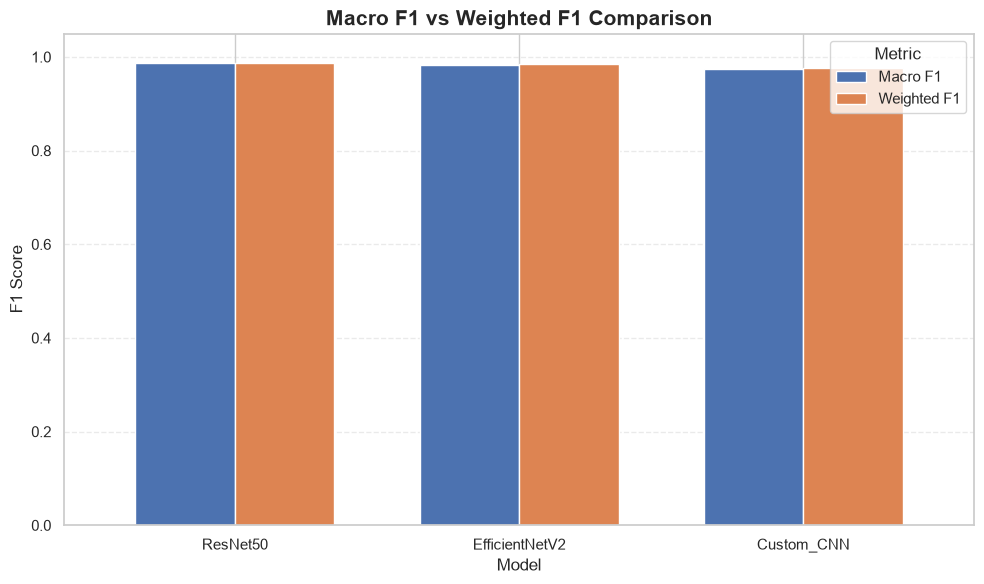

,Macro F1,Weighted F1,F1 Difference
Model,,,
ResNet50,0.9871,0.9876,0.0005
EfficientNetV2,0.9836,0.9844,0.0009
Custom_CNN,0.9746,0.9757,0.0011



F1 SCORE COMPARISON

ResNet50
Macro F1:       0.9871
Weighted F1:    0.9876
F1 Difference:  0.0005
Interpretation: Performance is consistent across classes.

EfficientNetV2
Macro F1:       0.9836
Weighted F1:    0.9844
F1 Difference:  0.0009
Interpretation: Performance is consistent across classes.

Custom_CNN
Macro F1:       0.9746
Weighted F1:    0.9757
F1 Difference:  0.0011
Interpretation: Performance is consistent across classes.


In [61]:
# ============================================================
# SECTION 13: MACRO VS WEIGHTED F1 COMPARISON
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# ------------------------------------------------------------
# 1. Extract F1 scores
# ------------------------------------------------------------

f1_comparison = comparison_df[
    ["Macro F1", "Weighted F1"]
].copy()

# ------------------------------------------------------------
# 2. Plot comparison
# ------------------------------------------------------------

ax = f1_comparison.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.7
)

plt.title(
    "Macro F1 vs Weighted F1 Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Model")
plt.ylabel("F1 Score")
plt.ylim(0, 1.05)

plt.xticks(rotation=0)

plt.legend(
    ["Macro F1", "Weighted F1"],
    title="Metric"
)

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. Calculate the difference between scores
# ------------------------------------------------------------

f1_comparison["F1 Difference"] = (
    f1_comparison["Weighted F1"]
    - f1_comparison["Macro F1"]
)

display(f1_comparison.round(4))

# ------------------------------------------------------------
# 4. Print interpretation
# ------------------------------------------------------------

print("\nF1 SCORE COMPARISON")
print("=" * 60)

for model_name, row in f1_comparison.iterrows():

    print(f"\n{model_name}")
    print(f"Macro F1:       {row['Macro F1']:.4f}")
    print(f"Weighted F1:    {row['Weighted F1']:.4f}")
    print(f"F1 Difference:  {row['F1 Difference']:.4f}")

    if abs(row["F1 Difference"]) < 0.01:
        print("Interpretation: Performance is consistent across classes.")
    elif row["F1 Difference"] > 0:
        print("Interpretation: Weighted F1 is higher; performance may vary across classes.")
    else:
        print("Interpretation: Macro F1 is higher than weighted F1.")

### Compare individual class performance

,ResNet50,EfficientNetV2,Custom_CNN
Class,,,
Annual Crop,0.9858,0.9824,0.9758
Forest,0.9934,0.9885,0.9935
Herbaceous Vegetation,0.9742,0.9715,0.9644
Highway,0.9880,0.9849,0.9630
Industrial Buildings,0.9890,0.9920,0.9756
Pasture,0.9721,0.9544,0.9545
Permanent Crop,0.9793,0.9812,0.9585
Residential Buildings,0.9964,0.9919,0.9839
River,0.9953,0.9905,0.9838


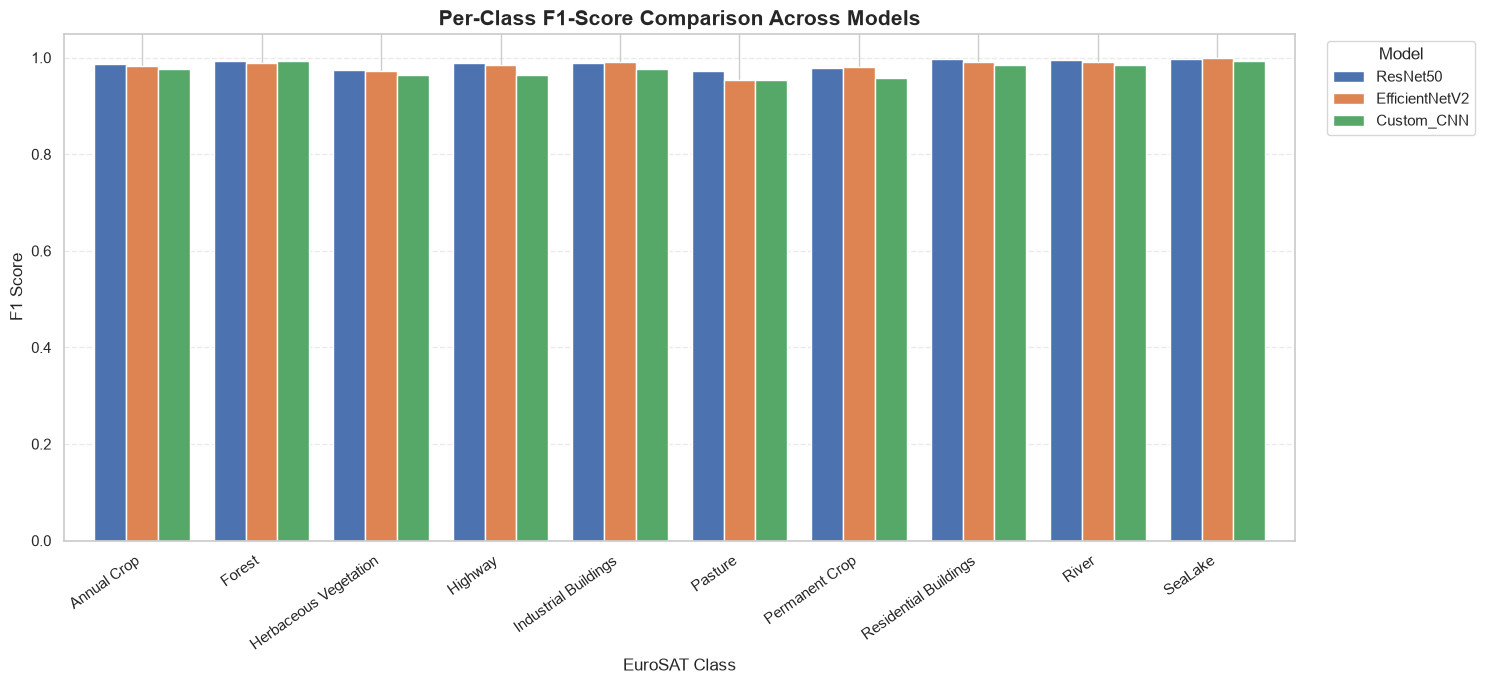


BEST MODEL PER CLASS
Annual Crop                    ResNet50           F1: 0.9858
Forest                         Custom_CNN         F1: 0.9935
Herbaceous Vegetation          ResNet50           F1: 0.9742
Highway                        ResNet50           F1: 0.9880
Industrial Buildings           EfficientNetV2     F1: 0.9920
Pasture                        ResNet50           F1: 0.9721
Permanent Crop                 EfficientNetV2     F1: 0.9812
Residential Buildings          ResNet50           F1: 0.9964
River                          ResNet50           F1: 0.9953
SeaLake                        EfficientNetV2     F1: 0.9984

AVERAGE PER-CLASS F1 SCORE


,Average Class F1
ResNet50,0.9871
EfficientNetV2,0.9836
Custom_CNN,0.9746


In [63]:
# ============================================================
# SECTION 14: PER-CLASS F1-SCORE COMPARISON
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 1. Extract F1 scores for every class and model
# ------------------------------------------------------------

class_f1_data = {}

for model_name, results in evaluation_results.items():

    # Convert classification report dictionary to DataFrame
    report = pd.DataFrame(results["report"]).transpose()

    # Extract F1 score for each class
    class_f1_data[model_name] = [
        report.loc[class_name, "f1-score"]
        for class_name in CLASS_NAMES
    ]

# ------------------------------------------------------------
# 2. Create comparison DataFrame
# ------------------------------------------------------------

class_f1_df = pd.DataFrame(
    class_f1_data,
    index=CLASS_NAMES
)

class_f1_df.index.name = "Class"

display(class_f1_df.round(4))

# ------------------------------------------------------------
# 3. Plot per-class F1 scores
# ------------------------------------------------------------

ax = class_f1_df.plot(
    kind="bar",
    figsize=(15, 7),
    width=0.8
)

plt.title(
    "Per-Class F1-Score Comparison Across Models",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("EuroSAT Class")
plt.ylabel("F1 Score")
plt.ylim(0, 1.05)

plt.xticks(
    rotation=35,
    ha="right"
)

plt.legend(
    title="Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. Identify the best model for each class
# ------------------------------------------------------------

print("\nBEST MODEL PER CLASS")
print("=" * 65)

for class_name, row in class_f1_df.iterrows():

    best_model = row.idxmax()
    best_score = row.max()

    print(
        f"{class_name:<30} "
        f"{best_model:<18} "
        f"F1: {best_score:.4f}"
    )

# ------------------------------------------------------------
# 5. Calculate average F1 score per model
# ------------------------------------------------------------

print("\nAVERAGE PER-CLASS F1 SCORE")
print("=" * 65)

average_class_f1 = class_f1_df.mean().sort_values(ascending=False)

display(
    average_class_f1.to_frame(
        name="Average Class F1"
    ).round(4)
)

### Compare inference speed and model complexity

,Total Parameters (M),Trainable Parameters (M),Total Inference Time (s),Average Image Time (ms),Images Per Second
Model,,,,,
ResNet50,23.5599,23.5599,25.0271,4.6347,215.7660
EfficientNetV2,51.1079,51.1079,38.5804,7.1445,139.9673
Custom_CNN,1.1787,1.1787,12.1508,2.2501,444.4165


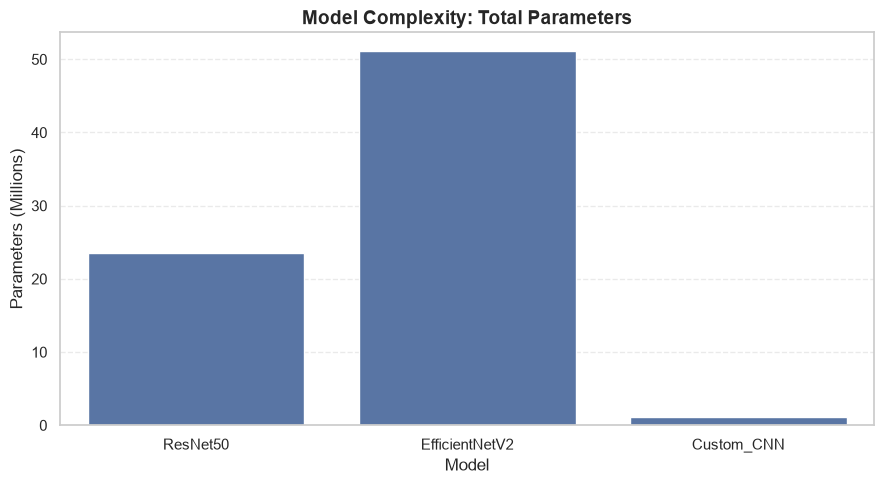

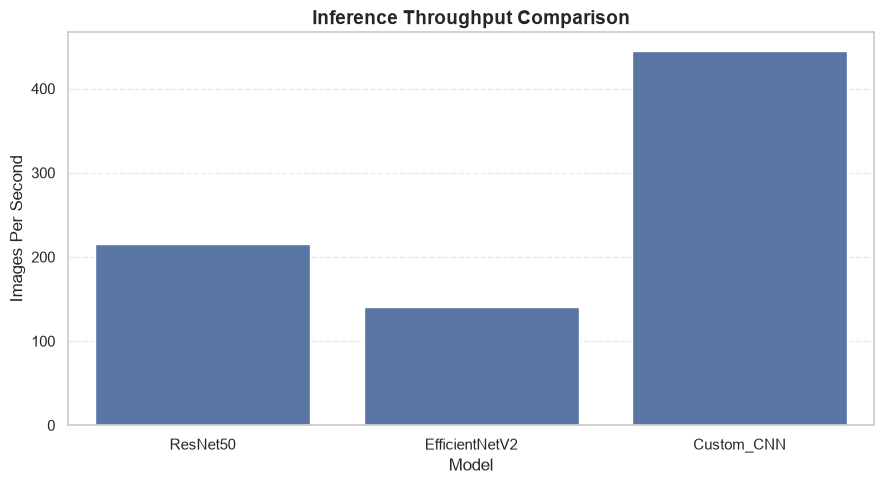

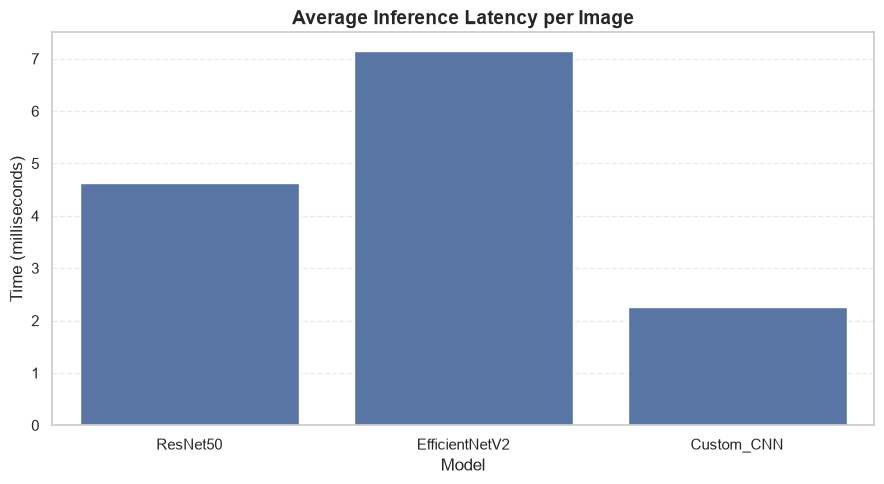


MODEL EFFICIENCY COMPARISON

Fastest model:
Custom_CNN

Smallest model:
Custom_CNN

Lowest inference latency:
Custom_CNN


In [65]:
# ============================================================
# SECTION 15: MODEL COMPLEXITY AND INFERENCE SPEED
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 1. Calculate model complexity
# ------------------------------------------------------------

model_information = []

for model_name, model in models.items():

    total_parameters = sum(
        parameter.numel()
        for parameter in model.parameters()
    )

    trainable_parameters = sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )

    model_information.append({
        "Model": model_name,
        "Total Parameters (M)": total_parameters / 1_000_000,
        "Trainable Parameters (M)": trainable_parameters / 1_000_000
    })

model_information_df = pd.DataFrame(model_information)

model_information_df.set_index("Model", inplace=True)

# ------------------------------------------------------------
# 2. Extract inference metrics
# ------------------------------------------------------------

inference_data = []

for model_name, results in evaluation_results.items():

    metrics = results["metrics"]

    inference_data.append({
        "Model": model_name,
        "Total Inference Time (s)": metrics["Total Inference Time (s)"],
        "Average Image Time (ms)": metrics["Average Image Time (ms)"],
        "Images Per Second": metrics["Images Per Second"]
    })

inference_df = pd.DataFrame(inference_data)

inference_df.set_index("Model", inplace=True)

# ------------------------------------------------------------
# 3. Combine complexity and inference information
# ------------------------------------------------------------

complexity_df = model_information_df.join(inference_df)

display(complexity_df.round(4))

# ------------------------------------------------------------
# 4. Plot model parameter counts
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

sns.barplot(
    x=complexity_df.index,
    y=complexity_df["Total Parameters (M)"]
)

plt.title(
    "Model Complexity: Total Parameters",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Model")
plt.ylabel("Parameters (Millions)")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. Plot inference throughput
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

sns.barplot(
    x=complexity_df.index,
    y=complexity_df["Images Per Second"]
)

plt.title(
    "Inference Throughput Comparison",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Model")
plt.ylabel("Images Per Second")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Plot average inference time per image
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

sns.barplot(
    x=complexity_df.index,
    y=complexity_df["Average Image Time (ms)"]
)

plt.title(
    "Average Inference Latency per Image",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Model")
plt.ylabel("Time (milliseconds)")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Print model efficiency ranking
# ------------------------------------------------------------

print("\nMODEL EFFICIENCY COMPARISON")
print("=" * 65)

print("\nFastest model:")
print(
    complexity_df["Images Per Second"]
    .idxmax()
)

print("\nSmallest model:")
print(
    complexity_df["Total Parameters (M)"]
    .idxmin()
)

print("\nLowest inference latency:")
print(
    complexity_df["Average Image Time (ms)"]
    .idxmin()
)

### Analyse classification errors


RESNET50
Incorrect predictions: 67


,Actual Class,Predicted Class,Count
19,Pasture,Herbaceous Vegetation,9
21,Permanent Crop,Annual Crop,7
22,Permanent Crop,Herbaceous Vegetation,6
4,Forest,Herbaceous Vegetation,5
14,Industrial Buildings,Highway,4
24,Permanent Crop,Pasture,4
15,Industrial Buildings,Residential Buildings,2
17,Pasture,Annual Crop,2
28,River,Highway,2
5,Forest,Pasture,2


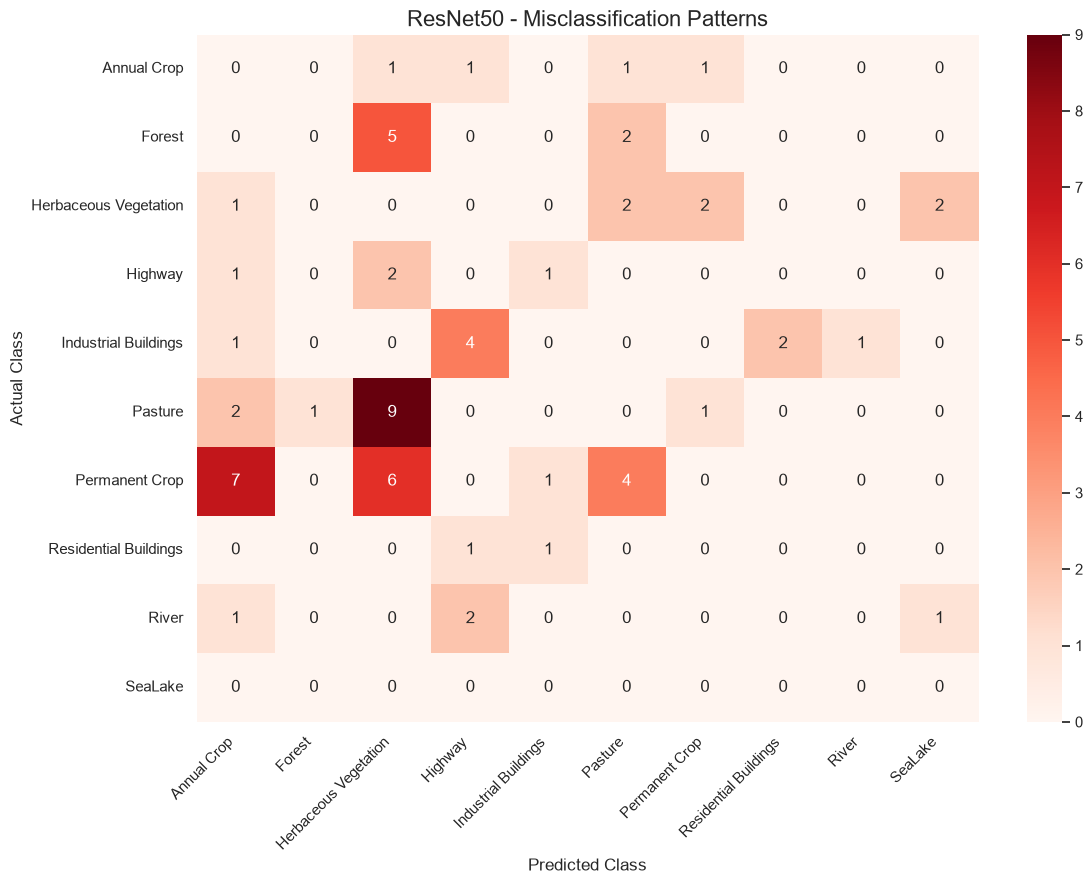


EFFICIENTNETV2
Incorrect predictions: 84


,Actual Class,Predicted Class,Count
18,Pasture,Herbaceous Vegetation,10
22,Permanent Crop,Herbaceous Vegetation,7
0,Annual Crop,Pasture,7
8,Herbaceous Vegetation,Pasture,6
15,Industrial Buildings,Residential Buildings,6
17,Pasture,Forest,5
21,Permanent Crop,Annual Crop,5
27,River,Highway,5
4,Forest,Herbaceous Vegetation,4
1,Annual Crop,Permanent Crop,3


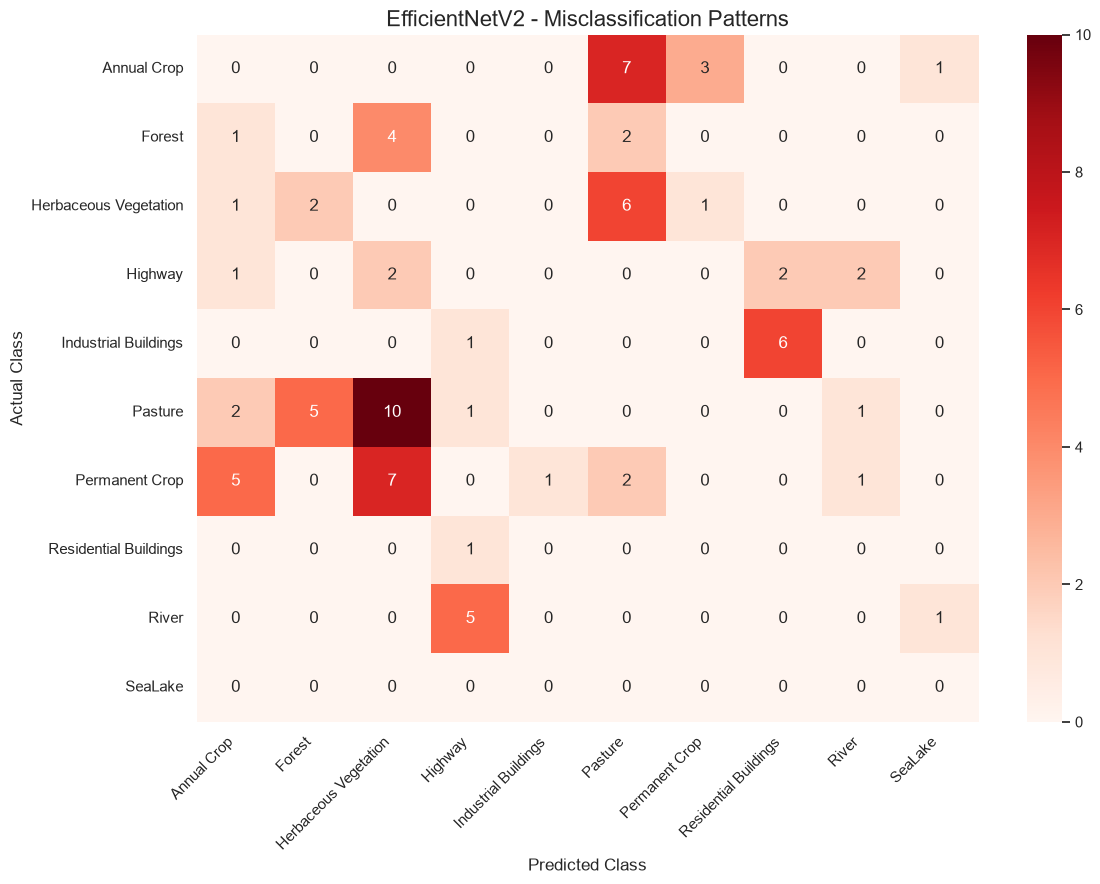


CUSTOM_CNN
Incorrect predictions: 131


,Actual Class,Predicted Class,Count
28,Permanent Crop,Herbaceous Vegetation,11
26,Permanent Crop,Annual Crop,11
17,Industrial Buildings,Highway,11
7,Herbaceous Vegetation,Pasture,8
19,Industrial Buildings,Residential Buildings,8
23,Pasture,Herbaceous Vegetation,8
38,River,SeaLake,6
8,Herbaceous Vegetation,Permanent Crop,6
15,Highway,Residential Buildings,5
36,River,Highway,5


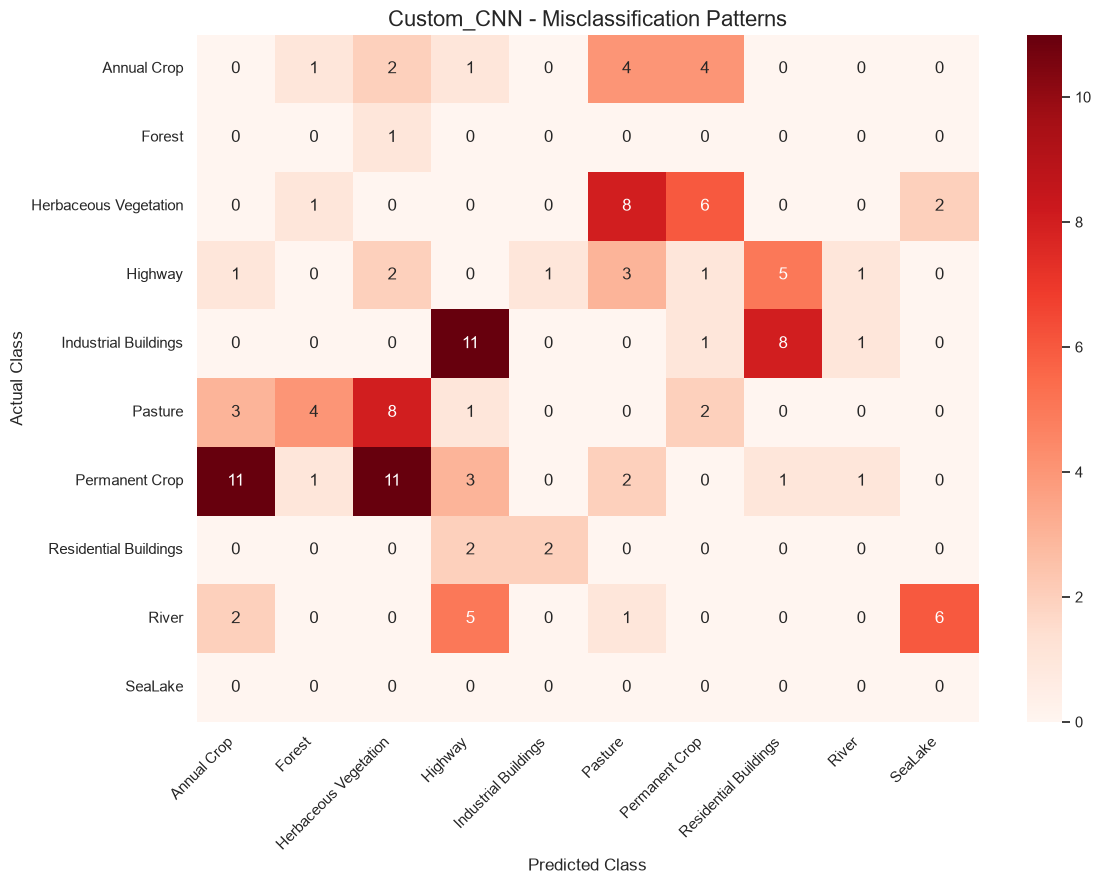

Classification error analysis completed.


In [66]:
# ============================================================
# SECTION 16: CLASSIFICATION ERROR ANALYSIS
# ============================================================

error_summaries = {}


for model_name, results in evaluation_results.items():

    predictions = results["predictions"]


    incorrect = predictions[
        predictions["Correct"] == False
    ].copy()


    print("\n" + "=" * 65)

    print(model_name.upper())

    print("=" * 65)

    print(
        "Incorrect predictions:",
        len(incorrect)
    )


    # Group errors by actual and predicted class
    error_summary = (

        incorrect.groupby(
            ["Actual Class", "Predicted Class"]
        )

        .size()

        .reset_index(name="Count")

        .sort_values(
            "Count",
            ascending=False
        )

    )


    error_summaries[model_name] = error_summary


    display(
        error_summary.head(15)
    )


    filename = (
        model_name.lower().replace(" ", "_")
        + "_classification_errors.csv"
    )


    error_summary.to_csv(
        METRICS_DIR / filename,
        index=False
    )


    # Misclassification matrix
    cm = results["confusion_matrix"].copy()

    np.fill_diagonal(
        cm,
        0
    )


    plt.figure(figsize=(12, 9))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Reds",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES
    )

    plt.title(
        f"{model_name} - Misclassification Patterns",
        fontsize=16
    )

    plt.xlabel("Predicted Class")

    plt.ylabel("Actual Class")

    plt.xticks(
        rotation=45,
        ha="right"
    )

    plt.yticks(rotation=0)

    plt.tight_layout()


    filename = (
        model_name.lower().replace(" ", "_")
        + "_misclassification_matrix.png"
    )


    plt.savefig(
        CONFUSION_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


print("Classification error analysis completed.")

### Compare prediction confidence

mean  median     std  count
Model          Prediction Type                               
Custom_CNN     Correct          0.9805  0.9984  0.0632   5269
               Incorrect        0.7468  0.7472  0.1767    131
EfficientNetV2 Correct          0.9938  1.0000  0.0385   5316
               Incorrect        0.8263  0.8876  0.1646     84
ResNet50       Correct          0.9935  0.9999  0.0361   5333
               Incorrect        0.8023  0.8575  0.1738     67

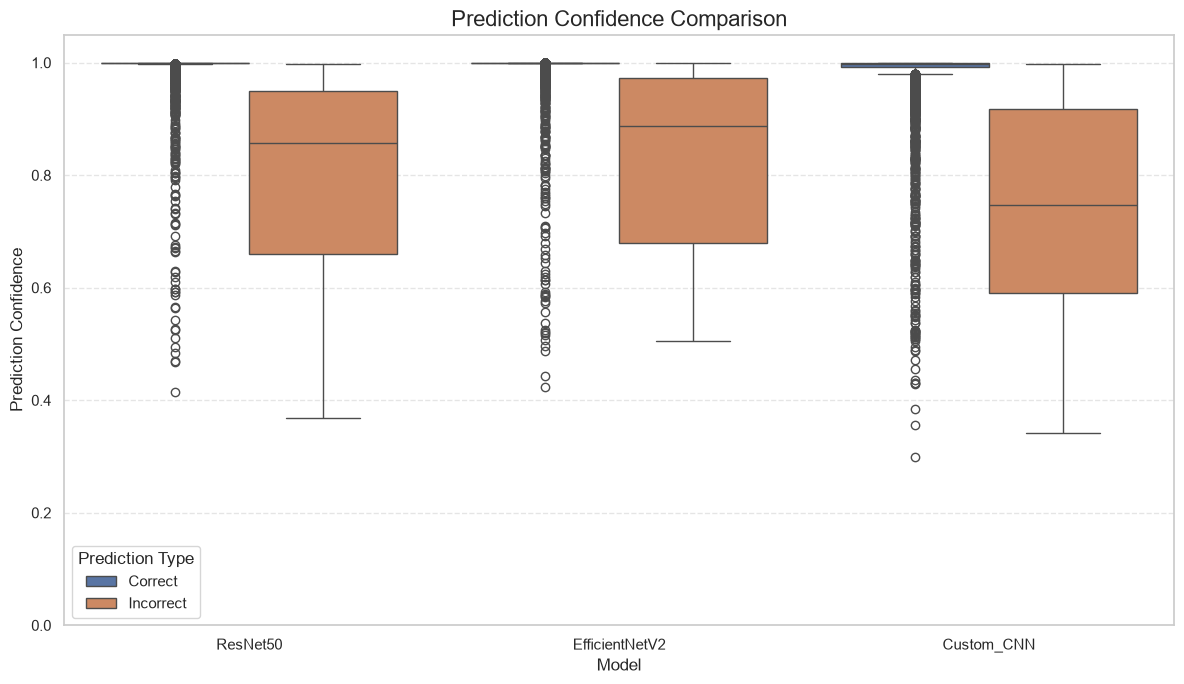

In [67]:
# ============================================================
# SECTION 17: PREDICTION CONFIDENCE ANALYSIS
# ============================================================

confidence_data = []


for model_name, results in evaluation_results.items():

    predictions = results["predictions"]


    correct_confidence = predictions.loc[
        predictions["Correct"],
        "Confidence"
    ]


    incorrect_confidence = predictions.loc[
        ~predictions["Correct"],
        "Confidence"
    ]


    for value in correct_confidence:

        confidence_data.append({

            "Model": model_name,

            "Prediction Type": "Correct",

            "Confidence": value

        })


    for value in incorrect_confidence:

        confidence_data.append({

            "Model": model_name,

            "Prediction Type": "Incorrect",

            "Confidence": value

        })


confidence_df = pd.DataFrame(
    confidence_data
)


display(
    confidence_df.groupby(
        ["Model", "Prediction Type"]
    )["Confidence"].agg(
        ["mean", "median", "std", "count"]
    ).round(4)
)


confidence_df.to_csv(
    METRICS_DIR / "prediction_confidence.csv",
    index=False
)


# Visualise confidence
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=confidence_df,
    x="Model",
    y="Confidence",
    hue="Prediction Type"
)

plt.title(
    "Prediction Confidence Comparison",
    fontsize=16
)

plt.xlabel("Model")

plt.ylabel("Prediction Confidence")

plt.ylim(0, 1.05)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.5
)

plt.tight_layout()

plt.savefig(
    GRAPHS_DIR / "prediction_confidence_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()

### Save all individual predictions

In [68]:
# ============================================================
# SECTION 18: SAVE ALL MODEL PREDICTIONS
# ============================================================

for model_name, results in evaluation_results.items():

    filename = (
        model_name.lower().replace(" ", "_")
        + "_predictions.csv"
    )

    output_path = (
        PREDICTIONS_DIR / filename
    )


    results["predictions"].to_csv(
        output_path,
        index=False
    )


    print(
        f"Saved {model_name} predictions:",
        output_path
    )


print("\nAll predictions saved.")

Saved ResNet50 predictions: C:\MyDocuments\GitHub Repository\image-classification-project\results\model_evaluation\predictions\resnet50_predictions.csv
Saved EfficientNetV2 predictions: C:\MyDocuments\GitHub Repository\image-classification-project\results\model_evaluation\predictions\efficientnetv2_predictions.csv
Saved Custom_CNN predictions: C:\MyDocuments\GitHub Repository\image-classification-project\results\model_evaluation\predictions\custom_cnn_predictions.csv

All predictions saved.


### Create RGB satellite images

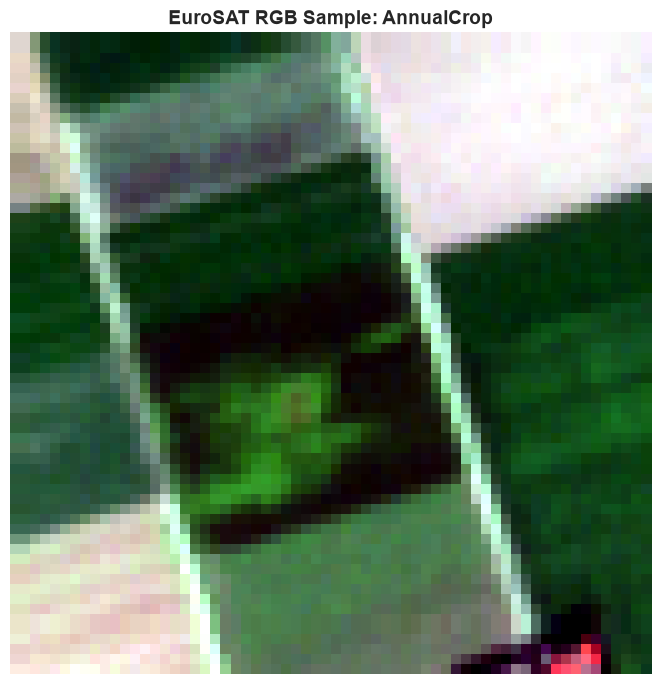

IMAGE INFORMATION
Image path: C:\MyDocuments\GitHub Repository\image-classification-project\data\raw\EuroSAT\test\AnnualCrop\AnnualCrop_1002.tif
Class: AnnualCrop
Number of bands: 13
Image width: 64
Image height: 64
Data type: uint16


In [70]:
# ============================================================
# SECTION 19: RGB VISUALISATION OF EURO-SAT IMAGES
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import rasterio
from pathlib import Path

# ------------------------------------------------------------
# 1. Define RGB image creation function
# ------------------------------------------------------------

def create_rgb_image(image_path):

    """
    Creates a natural-colour RGB image from a 13-band
    EuroSAT Sentinel-2 GeoTIFF image.

    Uses:
        Band 4 = Red
        Band 3 = Green
        Band 2 = Blue
    """

    with rasterio.open(image_path) as src:

        image = src.read().astype(np.float32)

    # Sentinel-2 bands are stored in this order:
    # B1, B2, B3, B4, B5, B6, B7,
    # B8, B8A, B9, B10, B11, B12

    red = image[3]
    green = image[2]
    blue = image[1]

    rgb = np.stack(
        [red, green, blue],
        axis=-1
    )

    # Percentile-based contrast stretching
    rgb_display = np.zeros_like(rgb)

    for channel in range(3):

        channel_data = rgb[:, :, channel]

        lower = np.percentile(channel_data, 2)
        upper = np.percentile(channel_data, 98)

        if upper > lower:

            rgb_display[:, :, channel] = np.clip(
                (channel_data - lower) / (upper - lower),
                0,
                1
            )

    return rgb_display


# ------------------------------------------------------------
# 2. Select a test image
# ------------------------------------------------------------

sample_image_path = test_df.iloc[0]["image_path"]

sample_class = test_df.iloc[0]["class_name"]

sample_rgb = create_rgb_image(
    sample_image_path
)


# ------------------------------------------------------------
# 3. Display RGB image
# ------------------------------------------------------------

plt.figure(figsize=(7, 7))

plt.imshow(sample_rgb)

plt.title(
    f"EuroSAT RGB Sample: {sample_class}",
    fontsize=14,
    fontweight="bold"
)

plt.axis("off")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. Display image information
# ------------------------------------------------------------

with rasterio.open(sample_image_path) as src:

    print("IMAGE INFORMATION")
    print("=" * 50)

    print(f"Image path: {sample_image_path}")
    print(f"Class: {sample_class}")
    print(f"Number of bands: {src.count}")
    print(f"Image width: {src.width}")
    print(f"Image height: {src.height}")
    print(f"Data type: {src.dtypes[0]}")

### Create individual classification example images


GENERATING CLASSIFICATION EXAMPLES: ResNet50


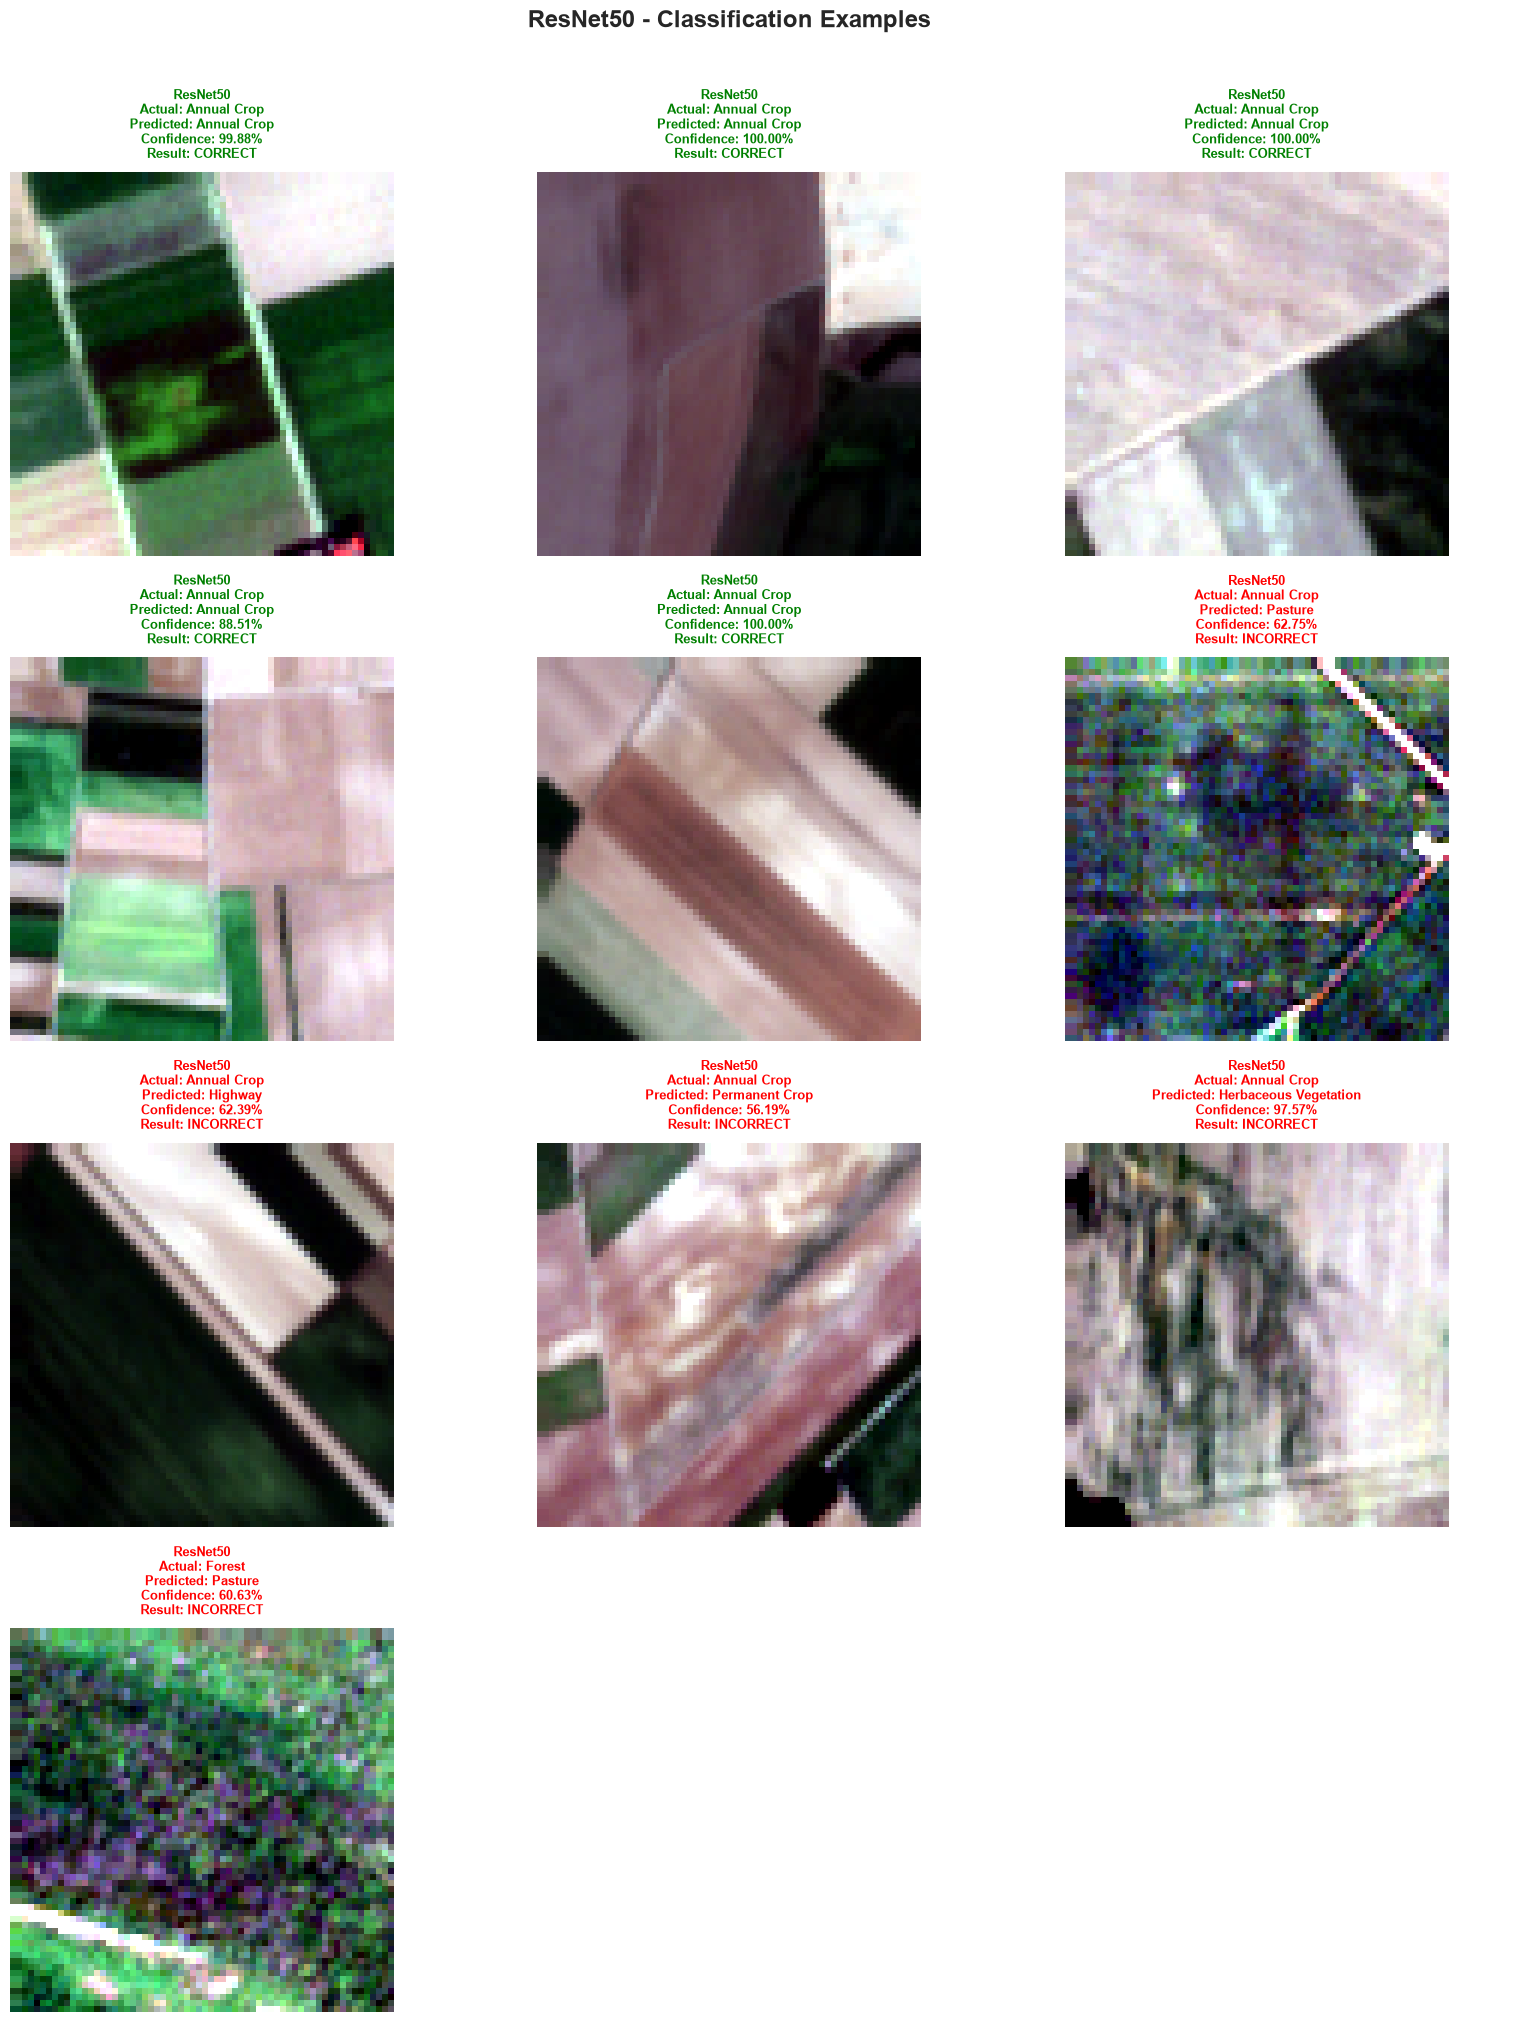

Correct examples saved: 5
Incorrect examples saved: 5
Saved in: C:\MyDocuments\GitHub Repository\image-classification-project\results\model_evaluation\classification_examples\resnet50

GENERATING CLASSIFICATION EXAMPLES: EfficientNetV2


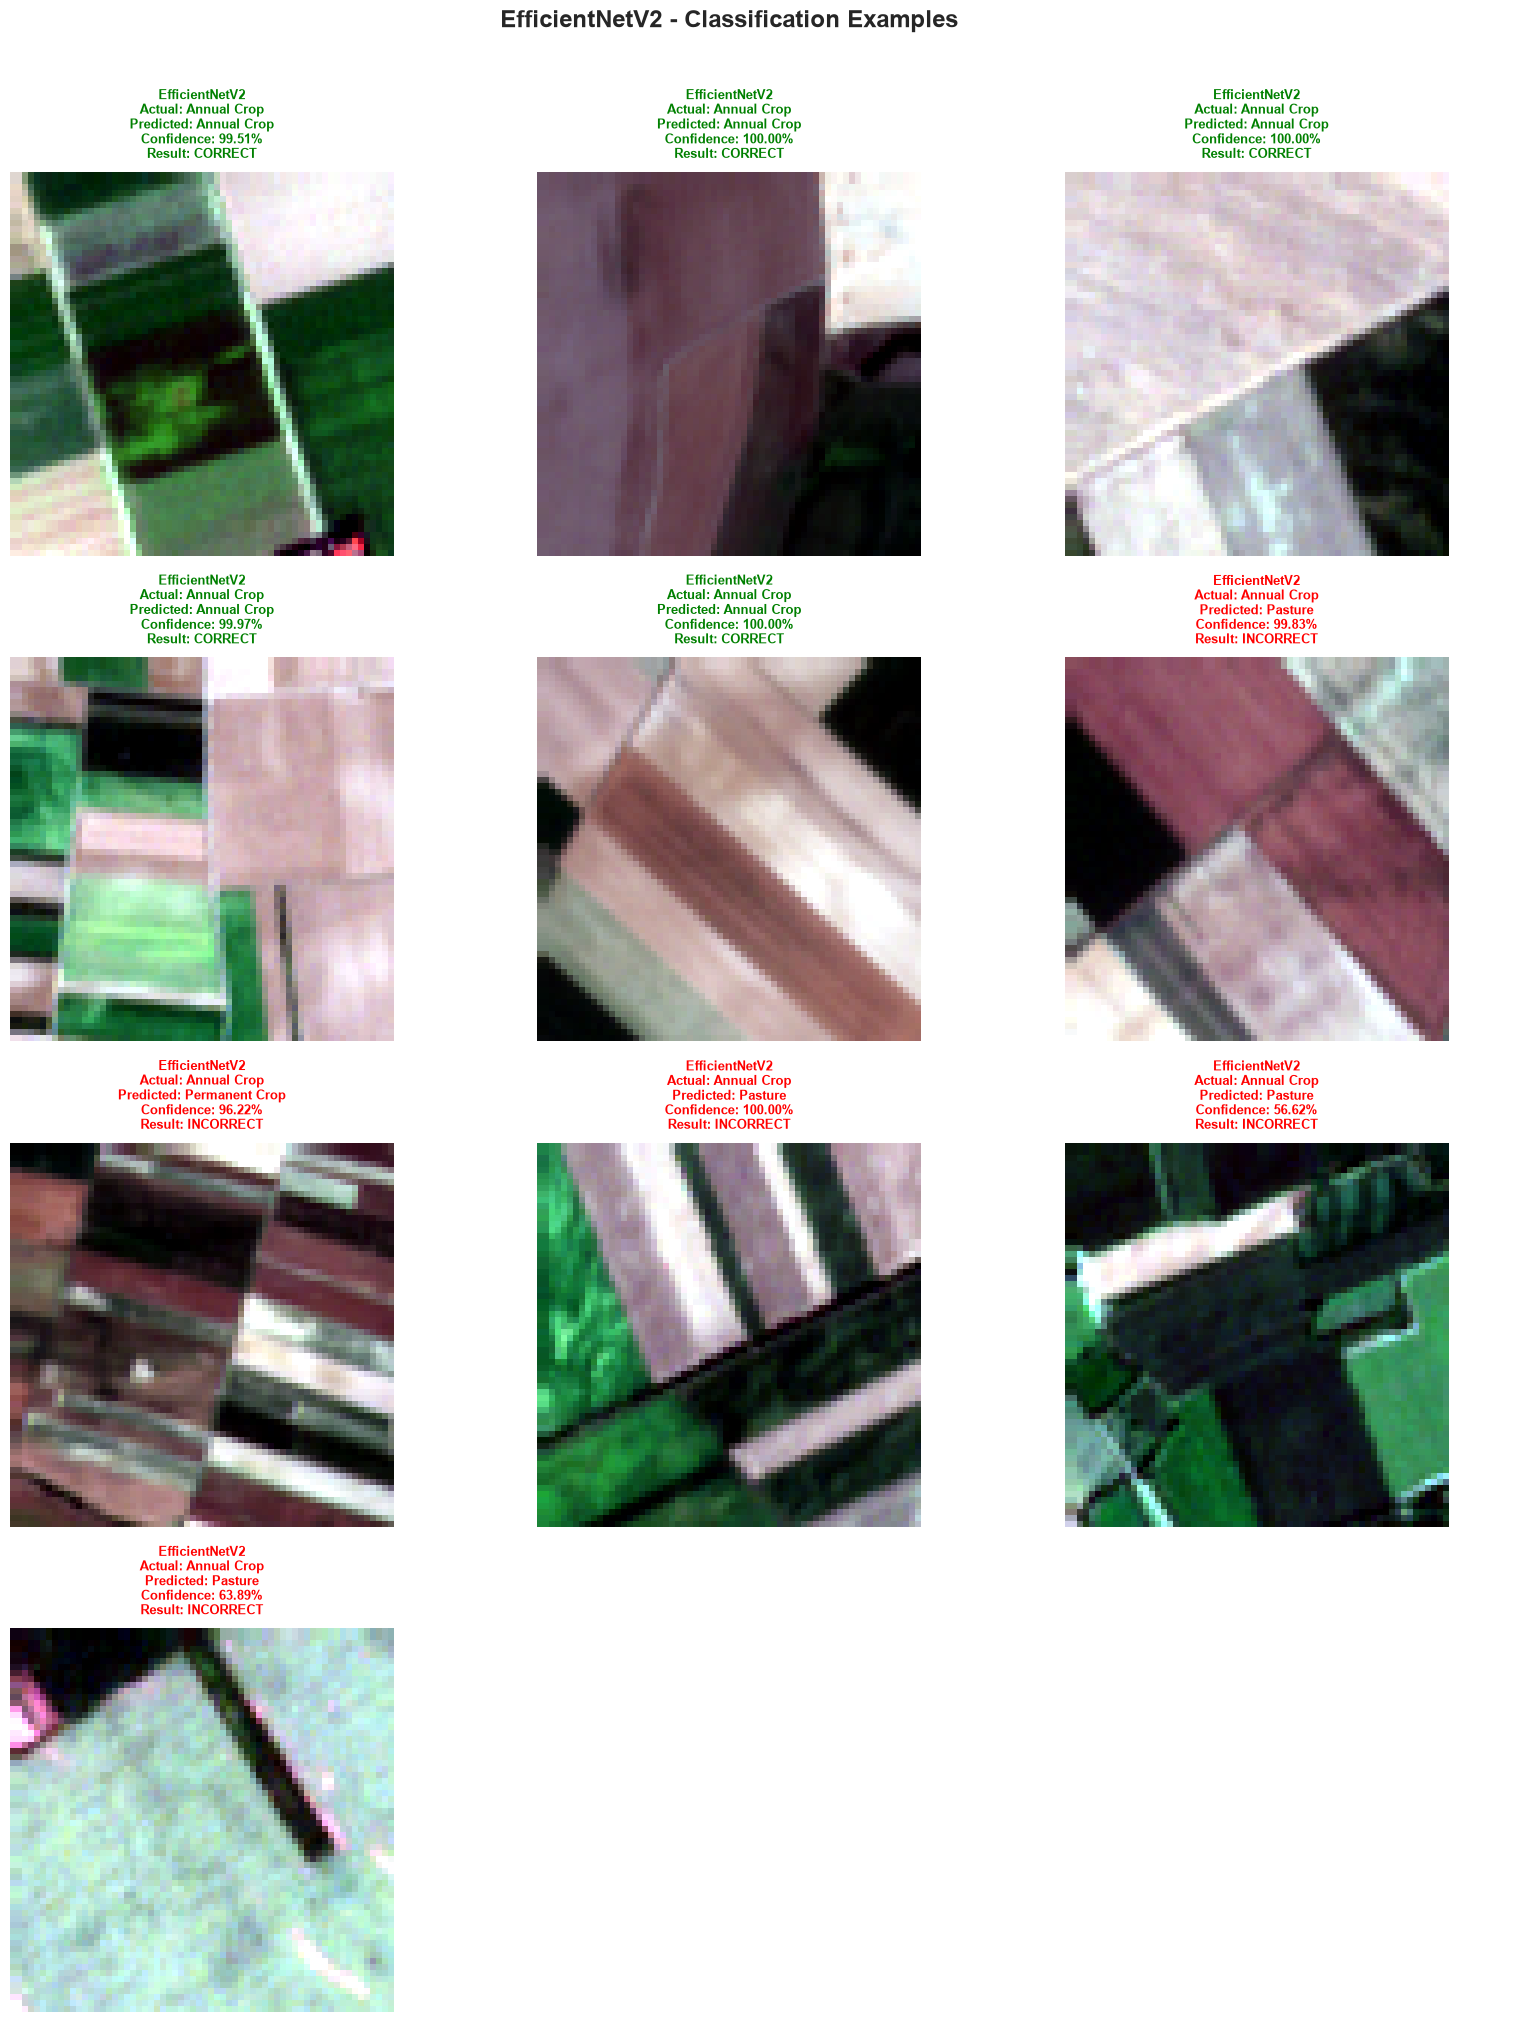

Correct examples saved: 5
Incorrect examples saved: 5
Saved in: C:\MyDocuments\GitHub Repository\image-classification-project\results\model_evaluation\classification_examples\efficientnetv2

GENERATING CLASSIFICATION EXAMPLES: Custom_CNN


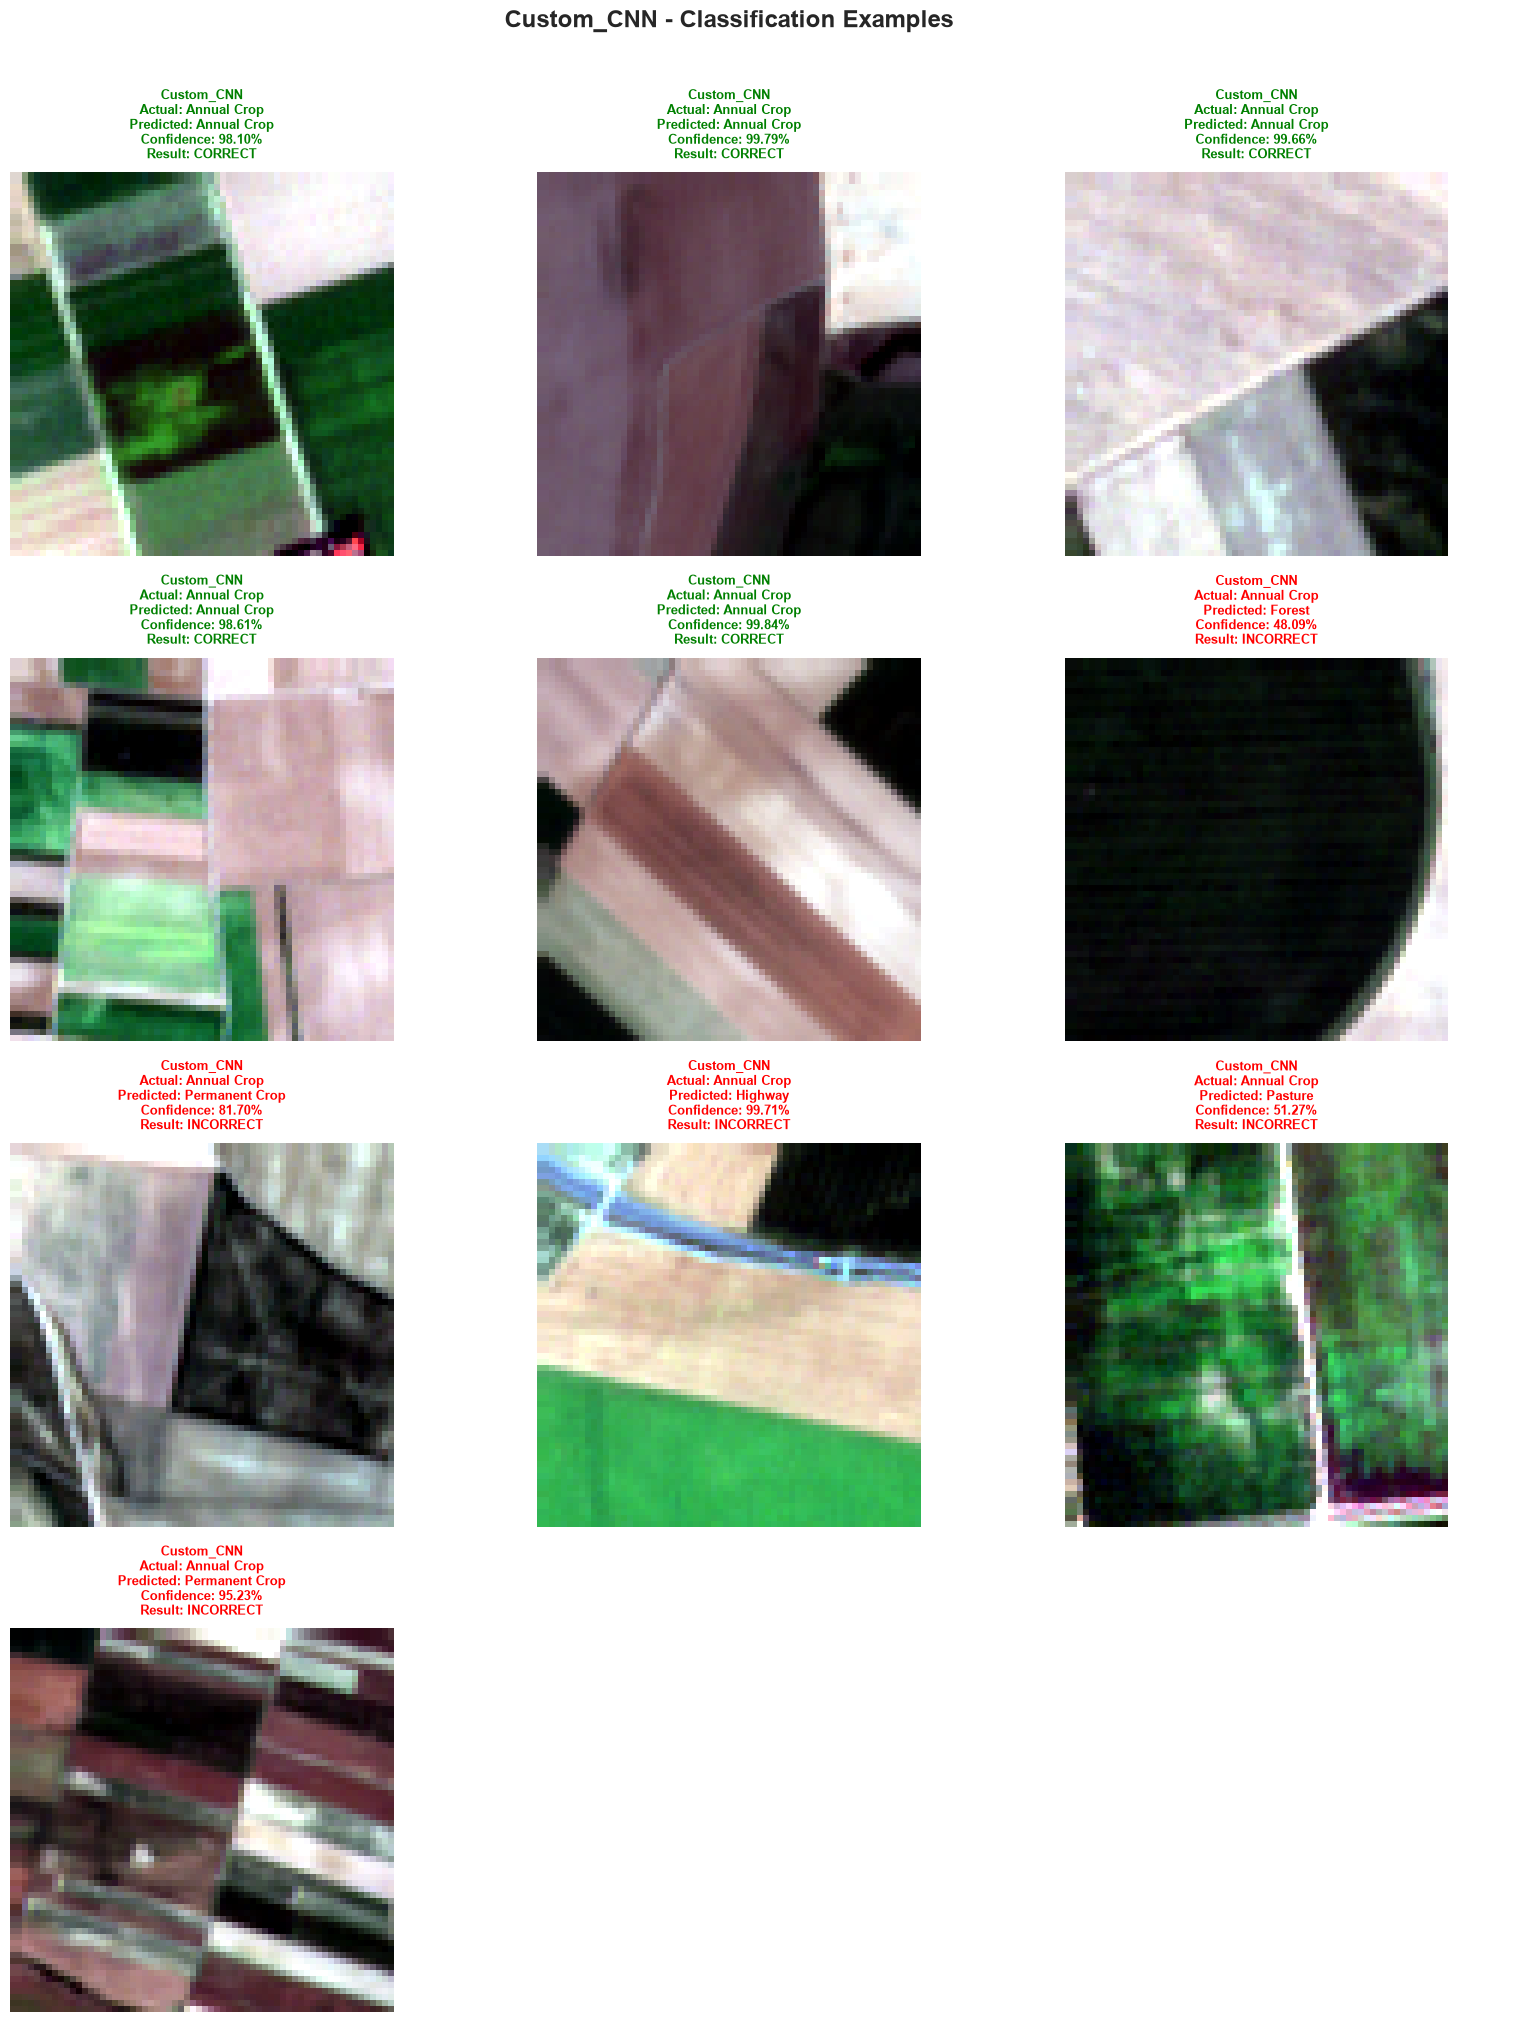

Correct examples saved: 5
Incorrect examples saved: 5
Saved in: C:\MyDocuments\GitHub Repository\image-classification-project\results\model_evaluation\classification_examples\custom_cnn

CLASSIFICATION EXAMPLE SUMMARY


,Model,Correct Examples,Incorrect Examples,Total Saved
0,ResNet50,5,5,10
1,EfficientNetV2,5,5,10
2,Custom_CNN,5,5,10



All classification examples have been saved and displayed.


In [74]:
# ============================================================
# SECTION 20: SAVE AND DISPLAY INDIVIDUAL CLASSIFICATION EXAMPLES
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

# Number of examples to display for each model
MAX_CORRECT = 5
MAX_INCORRECT = 5

# Number of columns in the visualisation grid
DISPLAY_COLUMNS = 3


# ------------------------------------------------------------
# 2. CREATE CLASSIFICATION VISUALISATION
# ------------------------------------------------------------

def display_classification_example(
    ax,
    model_name,
    image_path,
    actual_class,
    predicted_class,
    confidence,
    correct
):

    rgb_image = create_rgb_image(image_path)

    ax.imshow(rgb_image)
    ax.axis("off")

    status = "CORRECT" if correct else "INCORRECT"

    title_color = "green" if correct else "red"

    title = (
        f"{model_name}\n"
        f"Actual: {actual_class}\n"
        f"Predicted: {predicted_class}\n"
        f"Confidence: {confidence:.2%}\n"
        f"Result: {status}"
    )

    ax.set_title(
        title,
        fontsize=9,
        color=title_color,
        fontweight="bold",
        pad=10
    )


# ------------------------------------------------------------
# 3. SAVE CLASSIFICATION EXAMPLE
# ------------------------------------------------------------

def save_classification_example(
    model_name,
    image_path,
    actual_class,
    predicted_class,
    confidence,
    correct,
    output_path
):

    rgb_image = create_rgb_image(image_path)

    fig, ax = plt.subplots(figsize=(6, 6))

    ax.imshow(rgb_image)
    ax.axis("off")

    status = "CORRECT" if correct else "INCORRECT"

    title_color = "green" if correct else "red"

    title = (
        f"{model_name}\n"
        f"Actual: {actual_class}\n"
        f"Predicted: {predicted_class}\n"
        f"Confidence: {confidence:.2%}\n"
        f"Result: {status}"
    )

    ax.set_title(
        title,
        fontsize=12,
        color=title_color,
        fontweight="bold",
        pad=15
    )

    plt.tight_layout()

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close(fig)


# ------------------------------------------------------------
# 4. SELECT REPRESENTATIVE EXAMPLES
# ------------------------------------------------------------

def select_examples(prediction_df):

    correct_predictions = prediction_df[
        prediction_df["Correct"] == True
    ].copy()

    incorrect_predictions = prediction_df[
        prediction_df["Correct"] == False
    ].copy()

    # Select correct predictions
    correct_examples = correct_predictions.head(
        MAX_CORRECT
    )

    # Select incorrect predictions
    incorrect_examples = incorrect_predictions.head(
        MAX_INCORRECT
    )

    selected = pd.concat(
        [
            correct_examples,
            incorrect_examples
        ],
        ignore_index=True
    )

    return selected


# ------------------------------------------------------------
# 5. GENERATE, SAVE AND DISPLAY EXAMPLES FOR ALL MODELS
# ------------------------------------------------------------

example_summary = []

for model_name, results in evaluation_results.items():

    print("\n" + "=" * 70)
    print(f"GENERATING CLASSIFICATION EXAMPLES: {model_name}")
    print("=" * 70)

    model_folder = (
        EXAMPLES_DIR /
        model_name.lower().replace(" ", "_")
    )

    correct_folder = model_folder / "correct"

    incorrect_folder = model_folder / "incorrect"

    correct_folder.mkdir(
        parents=True,
        exist_ok=True
    )

    incorrect_folder.mkdir(
        parents=True,
        exist_ok=True
    )

    selected_examples = select_examples(
        results["predictions"]
    )

    correct_count = 0
    incorrect_count = 0

    # --------------------------------------------------------
    # Save individual images
    # --------------------------------------------------------

    for example_index, row in selected_examples.iterrows():

        actual_class = row["Actual Class"]
        predicted_class = row["Predicted Class"]
        confidence = float(row["Confidence"])
        correct = bool(row["Correct"])
        image_path = row["Image"]

        if correct:

            output_folder = correct_folder
            category = "correct"
            correct_count += 1

        else:

            output_folder = incorrect_folder
            category = "incorrect"
            incorrect_count += 1

        filename = (
            f"{category}_{example_index:03d}_"
            f"{actual_class}_to_{predicted_class}.png"
        )

        output_path = output_folder / filename

        save_classification_example(
            model_name=model_name,
            image_path=image_path,
            actual_class=actual_class,
            predicted_class=predicted_class,
            confidence=confidence,
            correct=correct,
            output_path=output_path
        )

    # --------------------------------------------------------
    # Display examples in notebook grid
    # --------------------------------------------------------

    number_of_examples = len(selected_examples)

    if number_of_examples > 0:

        display_columns = DISPLAY_COLUMNS

        display_rows = int(
            np.ceil(number_of_examples / display_columns)
        )

        fig, axes = plt.subplots(
            display_rows,
            display_columns,
            figsize=(16, 5 * display_rows)
        )

        axes = np.array(axes).reshape(-1)

        for ax in axes:
            ax.axis("off")

        for image_index, (_, row) in enumerate(
            selected_examples.iterrows()
        ):

            display_classification_example(
                ax=axes[image_index],
                model_name=model_name,
                image_path=row["Image"],
                actual_class=row["Actual Class"],
                predicted_class=row["Predicted Class"],
                confidence=float(row["Confidence"]),
                correct=bool(row["Correct"])
            )

        fig.suptitle(
            f"{model_name} - Classification Examples",
            fontsize=17,
            fontweight="bold",
            y=1.01
        )

        plt.tight_layout()
        plt.show()

    # --------------------------------------------------------
    # Record summary
    # --------------------------------------------------------

    example_summary.append({
        "Model": model_name,
        "Correct Examples": correct_count,
        "Incorrect Examples": incorrect_count,
        "Total Saved": correct_count + incorrect_count
    })

    print(f"Correct examples saved: {correct_count}")
    print(f"Incorrect examples saved: {incorrect_count}")
    print(f"Saved in: {model_folder}")


# ------------------------------------------------------------
# 6. DISPLAY SUMMARY
# ------------------------------------------------------------

example_summary_df = pd.DataFrame(example_summary)

print("\nCLASSIFICATION EXAMPLE SUMMARY")
print("=" * 70)

display(example_summary_df)

print("\nAll classification examples have been saved and displayed.")

### Compare predictions on identical images

In [75]:
# ============================================================
# SECTION 21: THREE-MODEL CLASSIFICATION COMPARISONS
# ============================================================

combined_predictions = {}


for model_name, results in evaluation_results.items():

    df = results["predictions"].copy()

    df = df.set_index("Image")

    combined_predictions[model_name] = df


# Find common image paths
common_images = set.intersection(
    *[
        set(df.index)
        for df in combined_predictions.values()
    ]
)


print(
    "Images evaluated by all models:",
    len(common_images)
)


# ------------------------------------------------------------
# FIND DISAGREEMENTS
# ------------------------------------------------------------

disagreement_images = []

for image_path in sorted(common_images):

    predicted_classes = [

        combined_predictions[model_name]
        .loc[image_path, "Predicted Class"]

        for model_name in models.keys()

    ]


    if len(set(predicted_classes)) > 1:

        disagreement_images.append(
            image_path
        )


print(
    "Images where models disagree:",
    len(disagreement_images)
)


# ------------------------------------------------------------
# FIND AGREEMENTS
# ------------------------------------------------------------

agreement_images = []

for image_path in sorted(common_images):

    predicted_classes = [

        combined_predictions[model_name]
        .loc[image_path, "Predicted Class"]

        for model_name in models.keys()

    ]


    if len(set(predicted_classes)) == 1:

        agreement_images.append(
            image_path
        )


print(
    "Images where all models agree:",
    len(agreement_images)
)


# ------------------------------------------------------------
# SAVE COMPARISON IMAGE FUNCTION
# ------------------------------------------------------------

def save_three_model_comparison(
    image_path,
    example_number,
    output_path
):

    rgb_image = create_rgb_image(
        image_path
    )


    actual_class = (
        combined_predictions["ResNet50"]
        .loc[image_path, "Actual Class"]
    )


    fig, ax = plt.subplots(
        figsize=(9, 9)
    )


    ax.imshow(rgb_image)

    ax.axis("off")


    title = (
        "EUROSAT MODEL CLASSIFICATION COMPARISON\n\n"
        f"Actual class: {actual_class}\n\n"
    )


    for model_name in models.keys():

        row = (
            combined_predictions[model_name]
            .loc[image_path]
        )


        predicted = row["Predicted Class"]

        confidence = row["Confidence"]

        correct = bool(row["Correct"])


        status = (
            "CORRECT"
            if correct
            else "INCORRECT"
        )


        title += (
            f"{model_name}: {predicted}\n"
            f"Confidence: {confidence:.2%} | {status}\n\n"
        )


    ax.set_title(
        title,
        fontsize=11,
        fontweight="bold",
        pad=15
    )


    plt.tight_layout()

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close(fig)


# ------------------------------------------------------------
# SAVE DISAGREEMENT EXAMPLES
# ------------------------------------------------------------

for example_number, image_path in enumerate(
    disagreement_images[:MAX_COMPARISON_EXAMPLES],
    start=1
):

    output_path = (
        COMPARISON_EXAMPLES_DIR /
        f"disagreement_{example_number:02d}.png"
    )


    save_three_model_comparison(
        image_path=image_path,
        example_number=example_number,
        output_path=output_path
    )


# ------------------------------------------------------------
# SAVE AGREEMENT EXAMPLES
# ------------------------------------------------------------

for example_number, image_path in enumerate(
    agreement_images[:MAX_COMPARISON_EXAMPLES],
    start=1
):

    output_path = (
        COMPARISON_EXAMPLES_DIR /
        f"agreement_{example_number:02d}.png"
    )


    save_three_model_comparison(
        image_path=image_path,
        example_number=example_number,
        output_path=output_path
    )


print("\nThree-model comparison images saved.")

Images evaluated by all models: 5400
Images where models disagree: 191
Images where all models agree: 5209

Three-model comparison images saved.


### Compare prediction confidence

,Model,Prediction Type,Mean Confidence,Median Confidence,Number of Predictions
0,ResNet50,Correct,0.9935,0.9999,5333
1,ResNet50,Incorrect,0.8023,0.8575,67
2,EfficientNetV2,Correct,0.9938,1.0000,5316
3,EfficientNetV2,Incorrect,0.8263,0.8876,84
4,Custom_CNN,Correct,0.9804,0.9984,5269
5,Custom_CNN,Incorrect,0.7468,0.7472,131


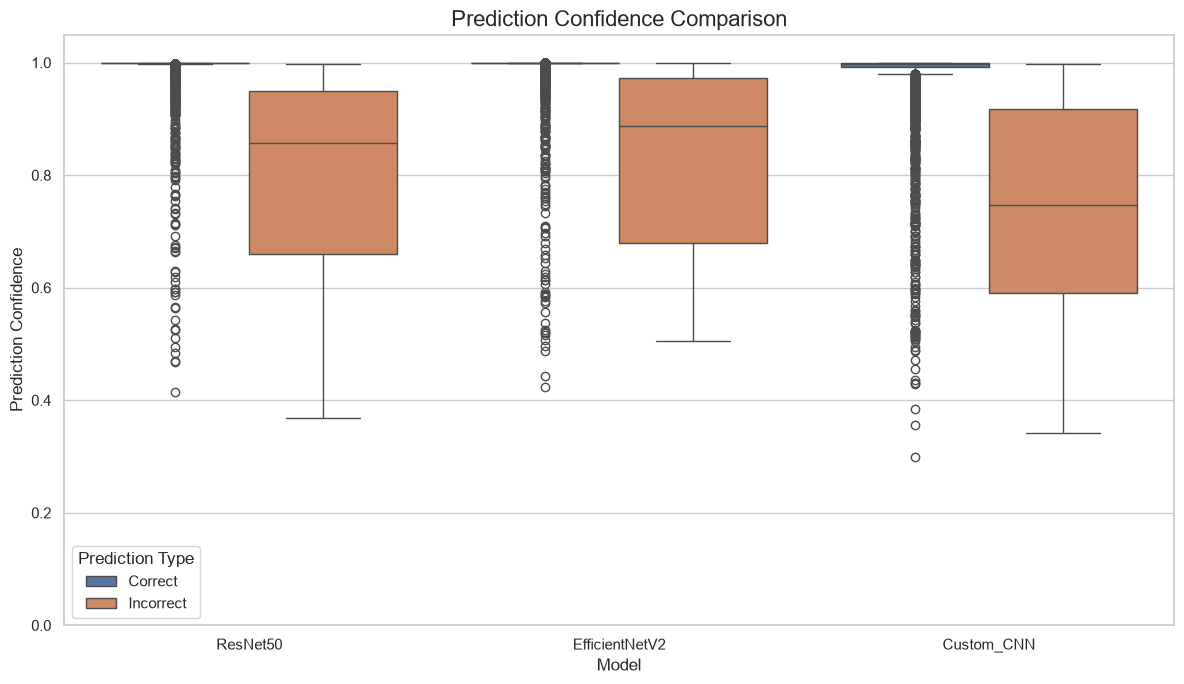

In [76]:
# ============================================================
# SECTION 22: CONFIDENCE COMPARISON
# ============================================================

confidence_summary = []


for model_name, results in evaluation_results.items():

    predictions = results["predictions"]


    for prediction_type, correct_value in [
        ("Correct", True),
        ("Incorrect", False)
    ]:

        selected = predictions[
            predictions["Correct"] == correct_value
        ]


        confidence_summary.append({

            "Model": model_name,

            "Prediction Type": prediction_type,

            "Mean Confidence": (
                selected["Confidence"].mean()
                if len(selected) > 0
                else np.nan
            ),

            "Median Confidence": (
                selected["Confidence"].median()
                if len(selected) > 0
                else np.nan
            ),

            "Number of Predictions": len(selected)

        })


confidence_summary_df = pd.DataFrame(
    confidence_summary
)


display(
    confidence_summary_df.round(4)
)


confidence_summary_df.to_csv(
    TABLES_DIR / "confidence_summary.csv",
    index=False
)


# Save confidence boxplot
confidence_data = []


for model_name, results in evaluation_results.items():

    predictions = results["predictions"]


    for _, row in predictions.iterrows():

        confidence_data.append({

            "Model": model_name,

            "Prediction Type": (
                "Correct"
                if row["Correct"]
                else "Incorrect"
            ),

            "Confidence": row["Confidence"]

        })


confidence_df = pd.DataFrame(
    confidence_data
)


plt.figure(figsize=(12, 7))

sns.boxplot(
    data=confidence_df,
    x="Model",
    y="Confidence",
    hue="Prediction Type"
)

plt.title(
    "Prediction Confidence Comparison",
    fontsize=16
)

plt.xlabel("Model")

plt.ylabel("Prediction Confidence")

plt.ylim(0, 1.05)

plt.tight_layout()

plt.savefig(
    GRAPHS_DIR / "prediction_confidence_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


confidence_df.to_csv(
    METRICS_DIR / "prediction_confidence.csv",
    index=False
)

### Create a final model ranking

FINAL MODEL PERFORMANCE RANKING


,Rank,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Balanced Accuracy,MCC,Cohen Kappa,Top-2 Accuracy,Inference Time (s),Average Image Time (ms),Images Per Second,Correct Predictions,Incorrect Predictions
Model,,,,,,,,,,,,,,,,,
ResNet50,1,0.9876,0.9875,0.9868,0.9871,0.9877,0.9876,0.9876,0.9868,0.9862,0.9862,0.9987,25.0271,4.6347,215.7660,5333,67
EfficientNetV2,2,0.9844,0.9838,0.9834,0.9836,0.9845,0.9844,0.9844,0.9834,0.9827,0.9827,0.9978,38.5804,7.1445,139.9673,5316,84
Custom_CNN,3,0.9757,0.9751,0.9744,0.9746,0.9759,0.9757,0.9757,0.9744,0.9730,0.9730,0.9944,12.1508,2.2501,444.4165,5269,131



BEST PERFORMING MODEL
-----------------------------------------------------------------
Model: ResNet50
Macro F1: 0.9871
Accuracy: 0.9876


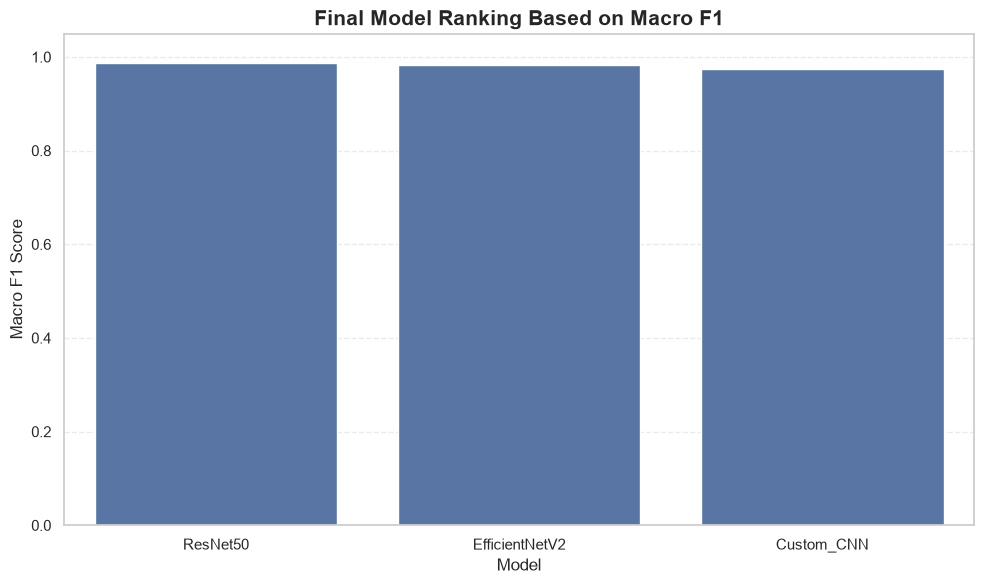


MODEL RANKING
-----------------------------------------------------------------
1. ResNet50 | Macro F1: 0.9871 | Accuracy: 0.9876
2. EfficientNetV2 | Macro F1: 0.9836 | Accuracy: 0.9844
3. Custom_CNN | Macro F1: 0.9746 | Accuracy: 0.9757


In [78]:
# ============================================================
# SECTION 23: FINAL MODEL RANKING
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 1. Create ranking DataFrame
# ------------------------------------------------------------

ranking_df = comparison_df.copy()

# Rank models using Macro F1
ranking_df = ranking_df.sort_values(
    by="Macro F1",
    ascending=False
)

# Add ranking position
ranking_df.insert(
    0,
    "Rank",
    range(1, len(ranking_df) + 1)
)

# ------------------------------------------------------------
# 2. Display final ranking
# ------------------------------------------------------------

print("=" * 65)
print("FINAL MODEL PERFORMANCE RANKING")
print("=" * 65)

display(ranking_df.round(4))

# ------------------------------------------------------------
# 3. Identify the best-performing model
# ------------------------------------------------------------

best_model = ranking_df.index[0]

best_macro_f1 = ranking_df.iloc[0]["Macro F1"]

best_accuracy = ranking_df.iloc[0]["Accuracy"]

print("\nBEST PERFORMING MODEL")
print("-" * 65)

print(f"Model: {best_model}")
print(f"Macro F1: {best_macro_f1:.4f}")
print(f"Accuracy: {best_accuracy:.4f}")

# ------------------------------------------------------------
# 4. Visualise final ranking
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.barplot(
    x=ranking_df.index,
    y=ranking_df["Macro F1"]
)

plt.title(
    "Final Model Ranking Based on Macro F1",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Model")
plt.ylabel("Macro F1 Score")
plt.ylim(0, 1.05)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. Print ranking interpretation
# ------------------------------------------------------------

print("\nMODEL RANKING")
print("-" * 65)

for position, (model_name, row) in enumerate(
    ranking_df.iterrows(),
    start=1
):

    print(
        f"{position}. {model_name} "
        f"| Macro F1: {row['Macro F1']:.4f} "
        f"| Accuracy: {row['Accuracy']:.4f}"
    )

### Save classification example summary

In [79]:
# ============================================================
# SECTION 24: CLASSIFICATION EXAMPLE SUMMARY
# ============================================================

example_summary_df = pd.DataFrame(
    example_summary
)


display(example_summary_df)


example_summary_df.to_csv(
    TABLES_DIR / "classification_example_summary.csv",
    index=False
)


print("Classification example summary saved.")

,Model,Correct Examples,Incorrect Examples,Total Saved
0,ResNet50,5,5,10
1,EfficientNetV2,5,5,10
2,Custom_CNN,5,5,10


Classification example summary saved.


### Export all results to CSV file

In [82]:
# ============================================================
# SECTION 25: EXPORT MODEL EVALUATION RESULTS
# ============================================================

# ------------------------------------------------------------
# 1. Create output directories
# ------------------------------------------------------------

TABLES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 2. Export model comparison
# ------------------------------------------------------------

comparison_path = (
    TABLES_DIR / "EuroSAT_Model_Comparison.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=True
)

# ------------------------------------------------------------
# 3. Export final model ranking
# ------------------------------------------------------------

ranking_path = (
    TABLES_DIR / "EuroSAT_Model_Ranking.csv"
)

ranking_df.to_csv(
    ranking_path,
    index=True
)

# ------------------------------------------------------------
# 4. Export per-class F1 scores
# ------------------------------------------------------------

class_f1_path = (
    TABLES_DIR / "EuroSAT_Per_Class_F1.csv"
)

class_f1_df.to_csv(
    class_f1_path,
    index=True
)

# ------------------------------------------------------------
# 5. Export model complexity and inference metrics
# ------------------------------------------------------------

complexity_path = (
    TABLES_DIR / "EuroSAT_Model_Complexity.csv"
)

complexity_df.to_csv(
    complexity_path,
    index=True
)

# ------------------------------------------------------------
# 6. Export individual classification predictions
# ------------------------------------------------------------

for model_name, results in evaluation_results.items():

    prediction_path = (
        TABLES_DIR /
        f"{model_name.lower()}_predictions.csv"
    )

    results["predictions"].to_csv(
        prediction_path,
        index=False
    )

# ------------------------------------------------------------
# 7. Display export summary
# ------------------------------------------------------------

print("=" * 65)
print("EVALUATION RESULTS EXPORTED SUCCESSFULLY")
print("=" * 65)

print(f"\nOutput directory: {TABLES_DIR}")

print("\nExported files:")

for file_path in TABLES_DIR.glob("*.csv"):
    print(f"- {file_path.name}")

EVALUATION RESULTS EXPORTED SUCCESSFULLY

Output directory: C:\MyDocuments\GitHub Repository\image-classification-project\results\model_evaluation\report_tables

Exported files:
- classification_example_summary.csv
- confidence_summary.csv
- custom_cnn_predictions.csv
- efficientnetv2_predictions.csv
- EuroSAT_Model_Comparison.csv
- EuroSAT_Model_Complexity.csv
- EuroSAT_Model_Ranking.csv
- EuroSAT_Per_Class_F1.csv
- resnet50_predictions.csv


### Save evaluation summary and configuration

In [83]:
# ============================================================
# SECTION 26: SAVE EVALUATION SUMMARY
# ============================================================

summary = {

    "dataset": "EuroSAT",

    "dataset_split": "Test",

    "number_of_classes": NUM_CLASSES,

    "input_channels": INPUT_CHANNELS,

    "image_dimensions": [
        IMAGE_SIZE,
        IMAGE_SIZE
    ],

    "number_of_test_images": len(test_dataset),

    "batch_size": BATCH_SIZE,

    "device": str(device),

    "random_seed": SEED,

    "primary_ranking_metric": "F1 (Macro)",

    "best_model": str(best_model),

    "models": {}

}


for model_name, results in evaluation_results.items():

    model_metrics = {}


    for key, value in results["metrics"].items():

        if isinstance(
            value,
            (np.integer, np.floating)
        ):

            value = value.item()


        model_metrics[key] = value


    summary["models"][model_name] = model_metrics


with open(
    METRICS_DIR / "evaluation_summary.json",
    "w"
) as file:

    json.dump(
        summary,
        file,
        indent=4
    )


print("Evaluation summary saved.")

Evaluation summary saved.


### Verify all saved outputs

In [84]:
# ============================================================
# SECTION 27: FINAL OUTPUT VERIFICATION
# ============================================================

print("\n" + "=" * 75)

print("EUROSAT MODEL EVALUATION COMPLETED")

print("=" * 75)


output_directories = [

    METRICS_DIR,

    CONFUSION_DIR,

    GRAPHS_DIR,

    PREDICTIONS_DIR,

    TABLES_DIR,

    EXAMPLES_DIR,

    COMPARISON_EXAMPLES_DIR

]


for directory in output_directories:

    files = [

        file for file in directory.rglob("*")

        if file.is_file()

    ]


    print("\n" + directory.name)

    print("-" * 60)

    print("Files generated:", len(files))


    for file in files[:20]:

        print("  ", file.name)


    if len(files) > 20:

        print(
            f"  ... and {len(files) - 20} more files"
        )


# Final model ranking
print("\nFINAL MODEL RANKING")

display(
    ranking_df[[
        "Rank",
        "Accuracy",
        "F1 (Macro)",
        "Balanced Accuracy"
    ]].round(4)
)


# Final output location
print("\nAll evaluation results saved to:")

print(OUTPUT_DIR.resolve())


# Verify Excel report
assert excel_path.exists()

# Verify predictions
for model_name in models:

    prediction_file = (
        PREDICTIONS_DIR /
        (
            model_name.lower().replace(" ", "_")
            + "_predictions.csv"
        )
    )

    assert prediction_file.exists()


# Verify classification examples
for model_name in models:

    model_folder = (
        EXAMPLES_DIR /
        model_name.lower().replace(" ", "_")
    )

    assert model_folder.exists()


print("\nAll required outputs verified successfully.")


EUROSAT MODEL EVALUATION COMPLETED

metrics
------------------------------------------------------------
Files generated: 6
   custom_cnn_classification_errors.csv
   efficientnetv2_classification_errors.csv
   evaluation_summary.json
   normalisation_statistics.json
   prediction_confidence.csv
   resnet50_classification_errors.csv

confusion_matrices
------------------------------------------------------------
Files generated: 12
   custom_cnn_confusion_matrix.csv
   custom_cnn_confusion_matrix.png
   custom_cnn_misclassification_matrix.png
   custom_cnn_normalised_confusion_matrix.png
   efficientnetv2_confusion_matrix.csv
   efficientnetv2_confusion_matrix.png
   efficientnetv2_misclassification_matrix.png
   efficientnetv2_normalised_confusion_matrix.png
   resnet50_confusion_matrix.csv
   resnet50_confusion_matrix.png
   resnet50_misclassification_matrix.png
   resnet50_normalised_confusion_matrix.png

comparison_graphs
-----------------------------------------------------------

KeyError: "['F1 (Macro)'] not in index"